# EDA & Visualisasi — Katalog Novel NovelLens

Notebook ini melengkapi `scripts/notebook/check.ipynb` (eksplorasi Spark SQL bebas) dengan tiga hal yang
belum ada di sana: **EDA sistematis** (univariat → bivariat → kualitas data), **visualisasi**
(dashboard Streamlit interaktif untuk end-user, notebook ini untuk laporan/analisis mendalam), dan
**analisis statistik lanjutan** — matriks korelasi multivariat, uji hipotesis (Kruskal-Wallis,
chi-square), reduksi dimensi (PCA), clustering tanpa label (KMeans + silhouette), dan association
rule mining (support/confidence/lift) pada ko-okurensi genre lengkap dengan visualisasi grafnya.

Berjalan di container `notebook` (Spark driver terpisah dari `pipeline`) — buka lewat
<http://localhost:8888>.

**Sumber data:**
- `s3a://clean-data/novels_clean` (Fase 2) — baris mentah per novel, dipakai untuk EDA univariat/bivariat.
- `s3a://curated-data/analytics/*` (Fase 3) — tabel agregat siap pakai, dipakai untuk visualisasi ringkasan
  supaya tidak menghitung ulang agregasi yang Spark SQL sudah kerjakan terdistribusi.

**Dua aturan analitik wajib** dari `Doc/data_contract.md` yang dipegang di seluruh notebook ini:
1. Pakai `weighted_rating` (Bayesian), bukan `rating_score` mentah, untuk peringkat apa pun.
2. Filter `is_rated_reliable` (>= 10 suara) saat menghitung rata-rata rating — sisanya sekadar belum dinilai.

## 0. Setup — Spark session, palet warna, gaya chart

In [1]:
from src.common.config import get_settings
from src.common.spark_session import build_spark_session
from src.common.storage import read_parquet_dir

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import pandas as pd

settings = get_settings()
spark = build_spark_session("notebook-eda")
print(f"Spark   : {spark.version}")
print(f"Master  : {settings.spark.master_url}")
print("Spark UI: http://localhost:8080")

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/certs/truststore.p12 -Djavax.net.ssl.trustStorePassword=changeit -Djavax.net.ssl.trustStoreType=PKCS12


Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/certs/truststore.p12 -Djavax.net.ssl.trustStorePassword=changeit -Djavax.net.ssl.trustStoreType=PKCS12


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/15 08:43:06 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


2026-10-15 08:43:07 | INFO     | src.common.spark_session | SparkSession aktif | app=notebook-eda | master=spark://spark-master:7077 | versi=3.5.3


Spark   : 3.5.3
Master  : spark://spark-master:7077
Spark UI: http://localhost:8080


### Palet & gaya

Warna dipilih sesuai *job*-nya, bukan selera — kategorikal untuk identitas, sequential (satu hue,
terang→gelap) untuk magnitudo, diverging (biru↔merah) untuk nilai berkutub (korelasi positif/negatif).
Urutan kategorikal ini FIXED (tidak pernah di-cycle acak) supaya warna yang sama selalu berarti entitas
yang sama di seluruh notebook.

In [2]:
# Kategorikal — urutan tetap, satu warna = satu identitas di SEMUA chart notebook ini.
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = CAT

# Sequential — satu hue (biru), untuk magnitudo (frekuensi, rating sebagai intensitas warna).
_SEQ_STEPS = ["#cde2fb", "#9ec5f4", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", _SEQ_STEPS)

# Diverging — biru (negatif) <-> merah (positif), titik tengah abu netral. Dipakai KHUSUS untuk
# nilai berkutub seperti koefisien korelasi — jangan dipakai untuk frekuensi biasa.
DIV = LinearSegmentedColormap.from_list("div_blue_red", ["#104281", "#f0efec", "#e34948"])

INK_PRIMARY, INK_SECONDARY, INK_MUTED, GRID, BASELINE, SURFACE = (
    "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb",
)

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK_SECONDARY,
    "text.color": INK_PRIMARY, "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlecolor": INK_PRIMARY, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True,
})


def style_ax(ax, hide_spines=("top", "right", "left")):
    """Spine tipis/recessive, grid hanya sumbu-y — konsisten di semua chart notebook ini."""
    for s in hide_spines:
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE)
    ax.grid(axis="x" if ax.get_visible() and False else "y", alpha=0.6)
    ax.tick_params(length=0)
    return ax


def load_table(name: str) -> pd.DataFrame:
    """Tabel agregat Fase 3 — kecil (ratusan baris), aman ditarik lewat pandas tanpa Spark."""
    return read_parquet_dir(settings.minio.bucket_curated, f"analytics/{name}")


print("Palet & gaya siap.")

Palet & gaya siap.


## 1. Memuat data

`novels_clean` adalah keluaran Fase 2: sentinel sudah dinormalkan jadi NULL, duplikat dibuang
berdasarkan `series_id`, `detail.csv` sudah digabungkan (baris tier `listing` → `full` di mana tersedia),
dan korpus teks sudah ditokenisasi. Kita ambil sebagai Spark DataFrame lalu tarik subset kolom yang
dipakai plotting ke pandas — jangan tarik seluruh 39 ribu baris x 40-an kolom termasuk array token,
itu tidak perlu untuk EDA numerik/kategorikal.

In [3]:
clean_uri = settings.minio.s3a_uri(settings.minio.bucket_clean, "novels_clean")
novels_sdf = spark.read.parquet(clean_uri).cache()

n_rows, n_cols = novels_sdf.count(), len(novels_sdf.columns)
print(f"{n_rows:,} baris x {n_cols} kolom")

EDA_COLS = [
    "series_id", "title", "metadata_tier", "type_origin", "type", "primary_genre", "n_genres",
    "year", "decade", "chapter_count", "length_bucket", "release_pace", "days_per_chapter",
    "rating_score", "rating_votes", "weighted_rating", "is_rated_reliable", "reading_list_count",
    "popularity_score", "has_synopsis", "synopsis_word_count", "token_count",
]
df = novels_sdf.select(*EDA_COLS).toPandas()
df.shape

26/10/15 08:43:08 WARN MetricsConfig: Cannot locate configuration: tried hadoop-metrics2-s3a-file-system.properties,hadoop-metrics2.properties


26/10/15 08:43:11 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


39,668 baris x 50 kolom


(39668, 22)

In [4]:
df.head(5)

,series_id,title,metadata_tier,type_origin,type,primary_genre,n_genres,year,decade,chapter_count,...,days_per_chapter,rating_score,rating_votes,weighted_rating,is_rated_reliable,reading_list_count,popularity_score,has_synopsis,synopsis_word_count,token_count
0,14,Against the Gods,full,CN,Web Novel,Action,8,2014.0,2010.0,2200.0,...,545.9,3.9,3640.0,3.8993,True,22509.0,18.2217,True,131.0,180
1,38,Stellar Transformation,full,CN,Web Novel,Action,7,2007.0,2000.0,680.0,...,417.9,4.2,1272.0,4.1957,True,12770.0,16.6041,True,117.0,132
2,148,The Bathroom Goddess,full,JP,Web Novel,Adventure,4,2012.0,2010.0,20.0,...,52.2,4.7,491.0,4.6791,True,4962.0,14.7082,True,106.0,69
3,157,The Legend of Sun Knight,full,CN,Published Novel,Action,6,2010.0,2010.0,104.0,...,280.5,4.7,662.0,4.6844,True,9387.0,15.6440,True,193.0,166
4,171,Young God Divine Armaments,full,JP,Web Novel,Action,8,2014.0,2010.0,215.0,...,127.3,3.5,193.0,3.5075,True,5374.0,13.8574,True,169.0,142


### Kelengkapan kolom (missingness)

Dataset ini **tidak punya satu pun `NaN` di sumber mentahnya** — kekosongan aslinya disandikan sebagai
sentinel (`0`, `"Unknown"`), yang sudah dikonversi Fase 2 menjadi NULL sungguhan (lihat `Doc/data_contract.md`).
Jadi grafik ini menunjukkan seberapa lengkap tiap kolom SETELAH pembersihan — bukan kegagalan parsing.

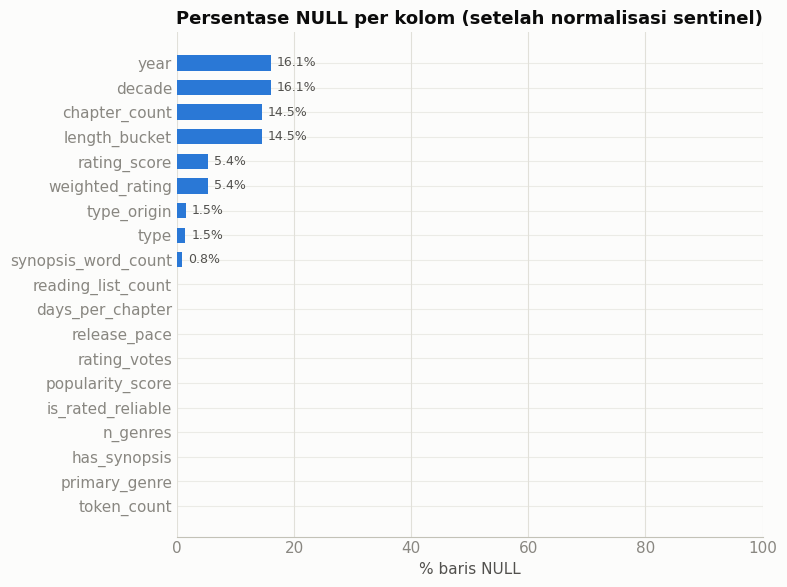

In [5]:
missing_pct = (df[EDA_COLS[3:]].isna().mean() * 100).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(missing_pct.index[::-1], missing_pct.values[::-1], color=BLUE, height=0.62)
for b, v in zip(bars, missing_pct.values[::-1]):
    if v > 0.5:
        ax.text(v + 1, b.get_y() + b.get_height() / 2, f"{v:.1f}%", va="center",
                fontsize=9, color=INK_SECONDARY)
ax.set_xlim(0, 100)
ax.set_title("Persentase NULL per kolom (setelah normalisasi sentinel)")
ax.set_xlabel("% baris NULL")
style_ax(ax)
plt.tight_layout()
plt.show()

**Cara baca:** `rating_score`/`rating_votes`/`weighted_rating` NULL besar itu WAJAR — itulah 16 baris
tier `listing` (novel yang gagal 404 di tahap `detail`) plus novel yang memang belum pernah dinilai
pembaca. `is_rated_reliable` memfilter populasi yang layak dirata-rata; jangan pernah `dropna()` polos
di sini karena itu akan ikut membuang baris yang sah (rating 0 suara ≠ data rusak).

## 2. EDA Univariat

### Komposisi katalog — tier metadata & asal negara

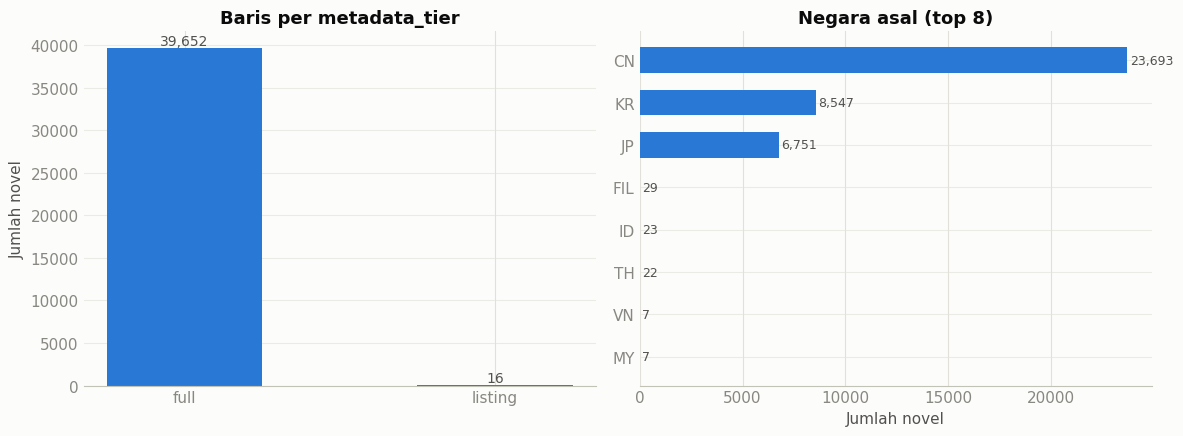

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

tier_counts = df["metadata_tier"].value_counts()
axes[0].bar(tier_counts.index, tier_counts.values, color=BLUE, width=0.5)
for i, v in enumerate(tier_counts.values):
    axes[0].text(i, v + n_rows * 0.01, f"{v:,}", ha="center", fontsize=10, color=INK_SECONDARY)
axes[0].set_title("Baris per metadata_tier")
axes[0].set_ylabel("Jumlah novel")
style_ax(axes[0])

origin_counts = df["type_origin"].value_counts().head(8)
axes[1].barh(origin_counts.index[::-1], origin_counts.values[::-1], color=BLUE, height=0.6)
for i, v in enumerate(origin_counts.values[::-1]):
    axes[1].text(v + n_rows * 0.003, i, f"{v:,}", va="center", fontsize=9, color=INK_SECONDARY)
axes[1].set_title("Negara asal (top 8)")
axes[1].set_xlabel("Jumlah novel")
style_ax(axes[1])

plt.tight_layout()
plt.show()

Dominasi CN/KR/JP ini yang membuat dataset pendamping asal Barat (mis. Goodreads Book Graph) sulit
ditautkan per-judul — dicatat sebagai batasan eksplisit, bukan disembunyikan.

### Distribusi metrik numerik utama

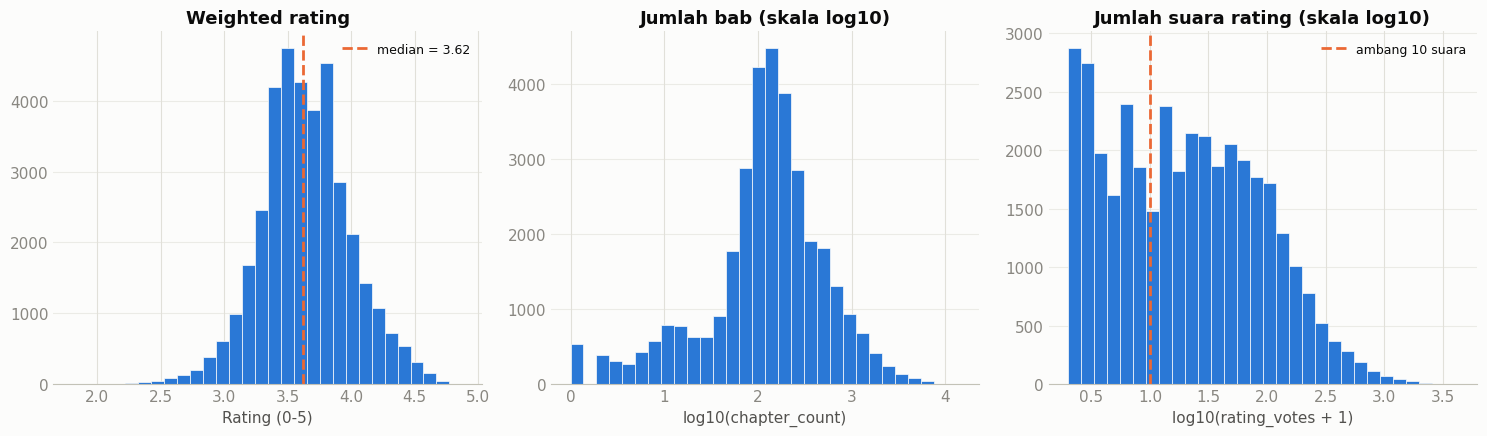

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].hist(df["weighted_rating"].dropna(), bins=30, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
axes[0].axvline(df["weighted_rating"].median(), color=ORANGE, linewidth=2, linestyle="--",
                label=f"median = {df['weighted_rating'].median():.2f}")
axes[0].set_title("Weighted rating")
axes[0].set_xlabel("Rating (0-5)")
axes[0].legend(frameon=False, fontsize=9)
style_ax(axes[0])

chapters = df["chapter_count"].dropna()
axes[1].hist(np.log10(chapters[chapters > 0]), bins=30, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
axes[1].set_title("Jumlah bab (skala log10)")
axes[1].set_xlabel("log10(chapter_count)")
style_ax(axes[1])

votes = df["rating_votes"].dropna()
axes[2].hist(np.log10(votes[votes > 0] + 1), bins=30, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
axes[2].axvline(np.log10(10), color=ORANGE, linewidth=2, linestyle="--", label="ambang 10 suara")
axes[2].set_title("Jumlah suara rating (skala log10)")
axes[2].set_xlabel("log10(rating_votes + 1)")
axes[2].legend(frameon=False, fontsize=9)
style_ax(axes[2])

plt.tight_layout()
plt.show()

Ketiganya berekor panjang (klasik untuk data popularitas): sebagian besar novel punya sedikit bab dan
sedikit suara, sebagian kecil sangat panjang/populer — itu sebabnya `chapter_count`/`rating_votes`
selalu dilihat di skala log, dan itu sebabnya `weighted_rating` (bukan rata-rata mentah) dipakai untuk
peringkat: ia menarik novel bersuara sedikit mendekati rata-rata global, bukan membiarkannya melejit
karena kebetulan 1 pembaca kasih nilai 5.

## 3. EDA Bivariat

### Panjang cerita vs rating

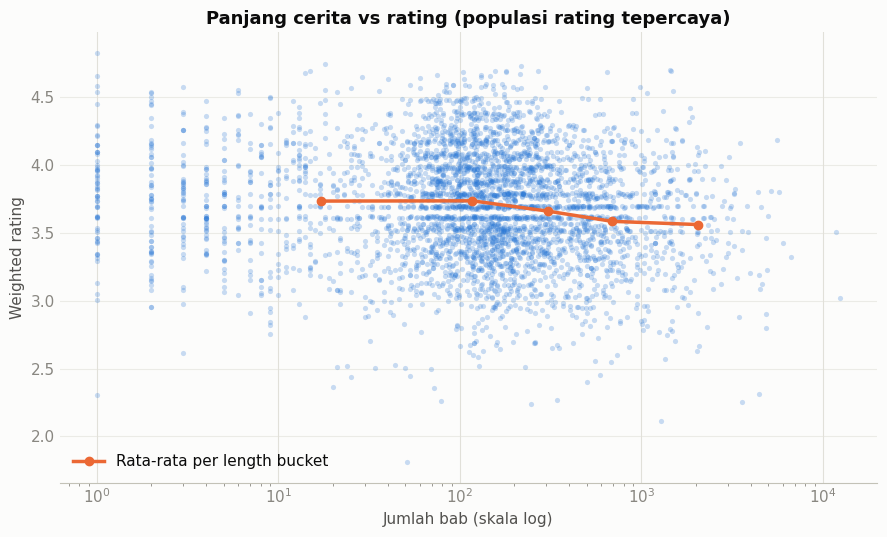

In [8]:
reliable = df[df["is_rated_reliable"] == True].dropna(subset=["chapter_count", "weighted_rating"])
sample = reliable.sample(min(4000, len(reliable)), random_state=42)  # scatter tetap terbaca

length_bucket = load_table("length_vs_rating").sort_values("length_bucket")

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(sample["chapter_count"], sample["weighted_rating"], s=14, color=BLUE, alpha=0.25,
           linewidths=0)
ax.plot(length_bucket["avg_chapters"], length_bucket["avg_weighted_rating"],
        color=ORANGE, linewidth=2.5, marker="o", markersize=6, label="Rata-rata per length bucket")
ax.set_xscale("log")
ax.set_xlabel("Jumlah bab (skala log)")
ax.set_ylabel("Weighted rating")
ax.set_title("Panjang cerita vs rating (populasi rating tepercaya)")
ax.legend(frameon=False, loc="lower left")
style_ax(ax)
plt.tight_layout()
plt.show()

### Kecepatan rilis & kekayaan teks vs rating

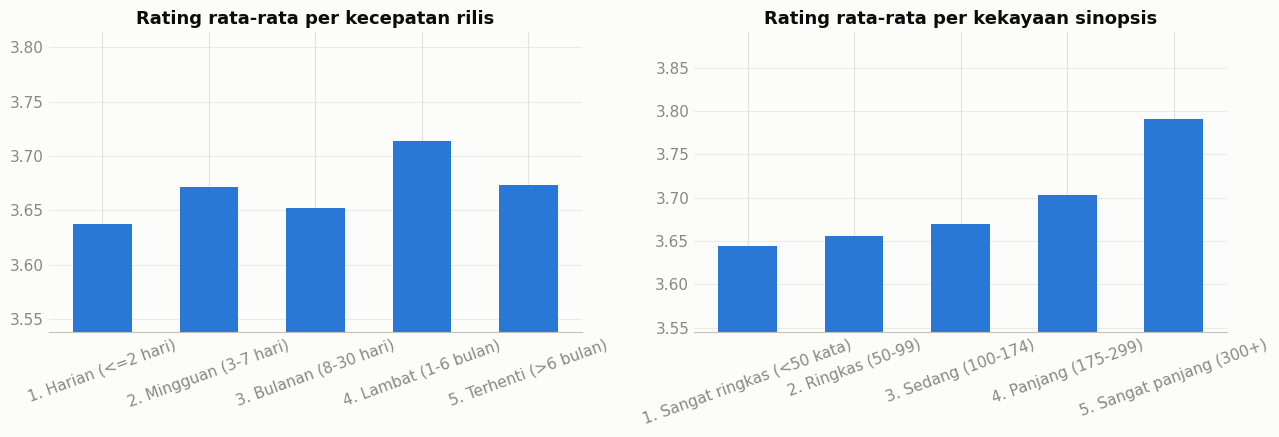

In [9]:
pace = load_table("release_pace_vs_rating")
richness = load_table("text_richness_vs_rating")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(pace["release_pace"], pace["avg_weighted_rating"], color=BLUE, width=0.55)
axes[0].set_ylim(pace["avg_weighted_rating"].min() - 0.1, pace["avg_weighted_rating"].max() + 0.1)
axes[0].set_title("Rating rata-rata per kecepatan rilis")
axes[0].tick_params(axis="x", rotation=20)
style_ax(axes[0])

axes[1].bar(richness["text_richness"], richness["avg_weighted_rating"], color=BLUE, width=0.55)
axes[1].set_ylim(richness["avg_weighted_rating"].min() - 0.1, richness["avg_weighted_rating"].max() + 0.1)
axes[1].set_title("Rating rata-rata per kekayaan sinopsis")
axes[1].tick_params(axis="x", rotation=20)
style_ax(axes[1])

plt.tight_layout()
plt.show()

### Ringkasan korelasi (Pearson r)

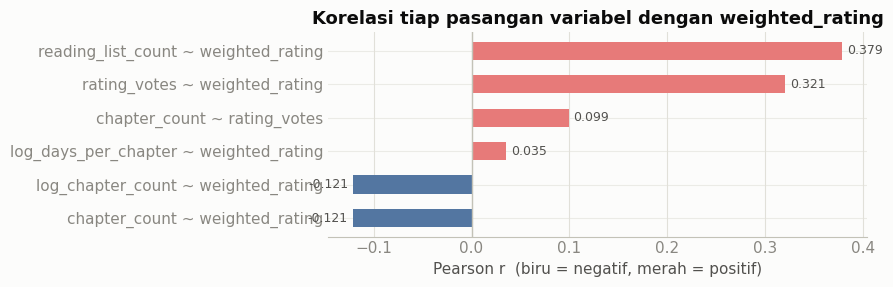

In [10]:
corr = load_table("correlation_metrics").sort_values("pearson_r")

fig, ax = plt.subplots(figsize=(9, max(3, 0.5 * len(corr))))
colors = [DIV(0.15) if r < 0 else DIV(0.85) for r in corr["pearson_r"]]
bars = ax.barh(corr["pair"], corr["pearson_r"], color=colors, height=0.55)
ax.axvline(0, color=BASELINE, linewidth=1)
for b, r in zip(bars, corr["pearson_r"]):
    ax.text(r + (0.005 if r >= 0 else -0.005), b.get_y() + b.get_height() / 2, f"{r:.3f}",
            va="center", ha="left" if r >= 0 else "right", fontsize=9, color=INK_SECONDARY)
ax.set_title("Korelasi tiap pasangan variabel dengan weighted_rating")
ax.set_xlabel("Pearson r  (biru = negatif, merah = positif)")
style_ax(ax)
plt.tight_layout()
plt.show()

Warna di sini **diverging** (biru↔merah), bukan kategorikal — karena nilainya sungguh berkutub (bisa
negatif/positif di sekitar nol), beda kasus dari chart frekuensi di atas yang semuanya nonnegatif.

**Korelasinya terbagi dua kelompok yang tidak boleh dibaca sama:**
1. `chapter_count`/`log_chapter_count`/`log_days_per_chapter` terhadap rating — **lemah** (|r| < 0.15).
   Efeknya nyata tapi kecil, konsisten dengan `Doc/data_contract.md`.
2. `rating_votes`/`reading_list_count` terhadap rating — **jauh lebih kuat** (r ≈ 0,32-0,38), TAPI ini
   bukan temuan independen: `rating_votes` adalah input langsung rumus `weighted_rating` itu sendiri
   (`WR = v/(v+m)·R + m/(v+m)·C` — makin banyak suara, makin sedikit ditarik ke rata-rata global C).
   Sebagian besar korelasi ini **mekanis by construction**, bukan bukti "novel populer pasti dinilai
   lebih baik". `reading_list_count` ikut kuat karena berkorelasi dengan `rating_votes` (sama-sama
   sinyal popularitas), bukan mekanisme rating yang terpisah.

## 4. Analisis Genre

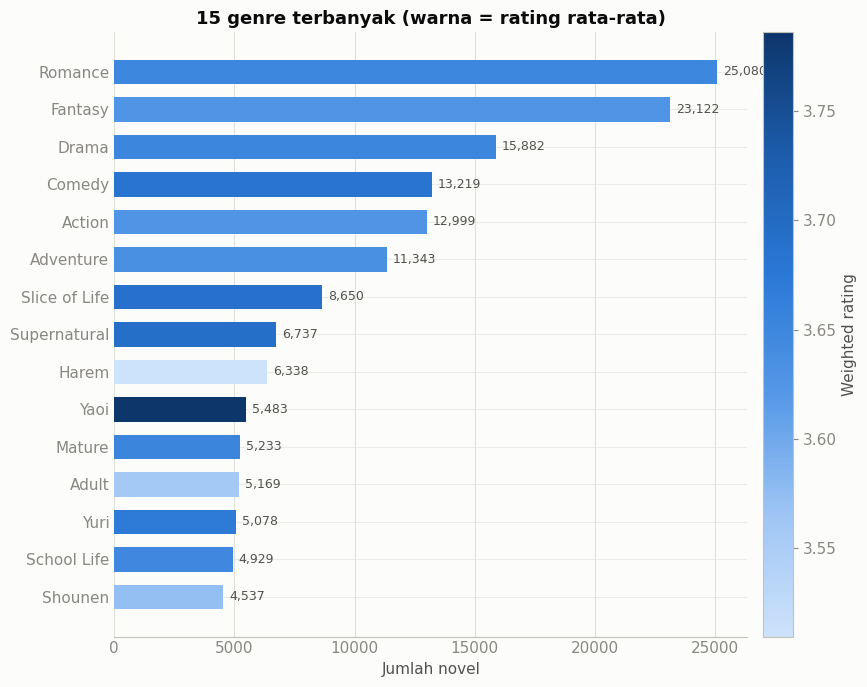

In [11]:
genre_freq = load_table("genre_frequency").nlargest(15, "n_novels").sort_values("n_novels")

norm = plt.Normalize(genre_freq["avg_weighted_rating"].min(), genre_freq["avg_weighted_rating"].max())
colors = SEQ_BLUE(norm(genre_freq["avg_weighted_rating"]))

fig, ax = plt.subplots(figsize=(9, 7))
bars = ax.barh(genre_freq["genre"], genre_freq["n_novels"], color=colors, height=0.65)
for b, v in zip(bars, genre_freq["n_novels"]):
    ax.text(v + max(genre_freq['n_novels']) * 0.01, b.get_y() + b.get_height() / 2, f"{v:,}",
            va="center", fontsize=9, color=INK_SECONDARY)
ax.set_title("15 genre terbanyak (warna = rating rata-rata)")
ax.set_xlabel("Jumlah novel")
sm = plt.cm.ScalarMappable(cmap=SEQ_BLUE, norm=norm)
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label("Weighted rating")
style_ax(ax)
plt.tight_layout()
plt.show()

**Perhatikan:** genre TERBANYAK belum tentu genre TERBAIK dinilai — itulah kenapa warna (magnitudo
kedua) dipisah dari posisi/panjang batang (magnitudo pertama), bukan digabung jadi satu angka.

### Peta pasar: genre × negara asal

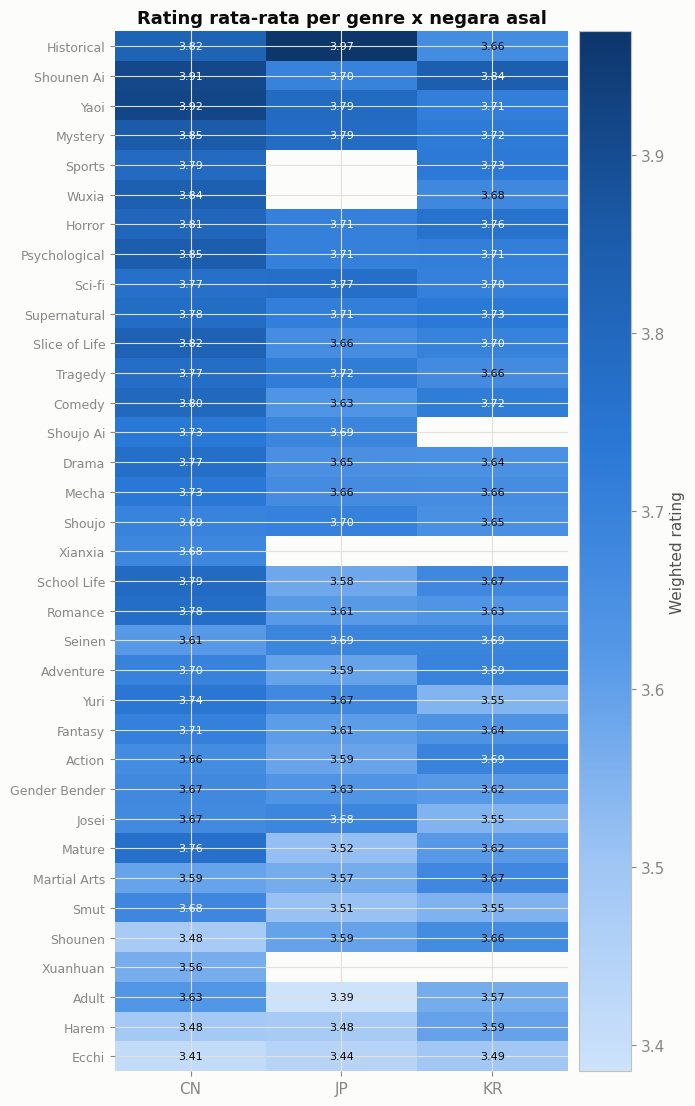

In [12]:
origin_matrix = load_table("genre_origin_matrix")
pivot = origin_matrix.pivot(index="genre", columns="type_origin", values="avg_weighted_rating")
pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(7, max(6, 0.32 * len(pivot))))
im = ax.imshow(pivot.values, cmap=SEQ_BLUE, aspect="auto")
ax.set_xticks(range(len(pivot.columns)), pivot.columns)
ax.set_yticks(range(len(pivot.index)), pivot.index, fontsize=9)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                    color=SURFACE if v > np.nanmean(pivot.values) else INK_PRIMARY)
ax.set_title("Rating rata-rata per genre x negara asal")
for spine in ax.spines.values():
    spine.set_visible(False)
fig.colorbar(im, ax=ax, pad=0.02, label="Weighted rating")
plt.tight_layout()
plt.show()

Sel kosong = kombinasi dengan kurang dari 25 novel — sengaja tidak dihitung supaya tidak ada rata-rata
yang bersandar pada segelintir judul (lihat `MIN_GROUP_SUPPORT` di `phase3_explore.py`).

## 5. Analisis Teks (Sinopsis)

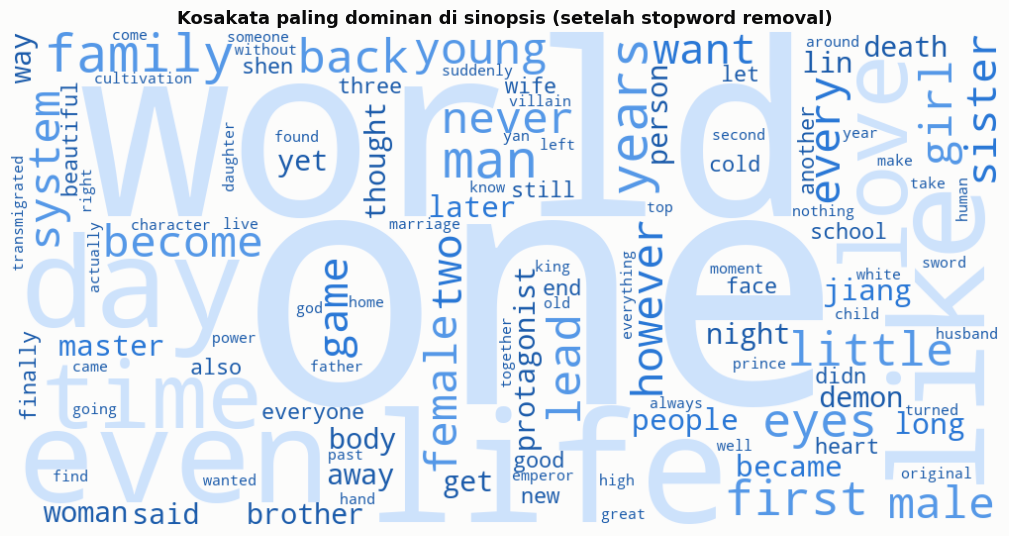

In [13]:
from wordcloud import WordCloud

tokens = load_table("top_tokens")
freqs = dict(zip(tokens["token"], tokens["freq"]))

_seq_hex = _SEQ_STEPS


def _blue_color_func(word, font_size, position, orientation, random_state=None, **kwargs):
    # Satu hue (biru), intensitas naik dengan ukuran font -> konsisten dengan sequential ramp palet.
    idx = min(len(_seq_hex) - 1, int((font_size / 90) * len(_seq_hex)))
    return _seq_hex[max(0, len(_seq_hex) - 1 - idx)]


cloud = WordCloud(width=1000, height=500, background_color=SURFACE, color_func=_blue_color_func,
                   prefer_horizontal=0.95, max_words=120).generate_from_frequencies(freqs)

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.imshow(cloud, interpolation="bilinear")
ax.axis("off")
ax.set_title("Kosakata paling dominan di sinopsis (setelah stopword removal)")
plt.tight_layout()
plt.show()

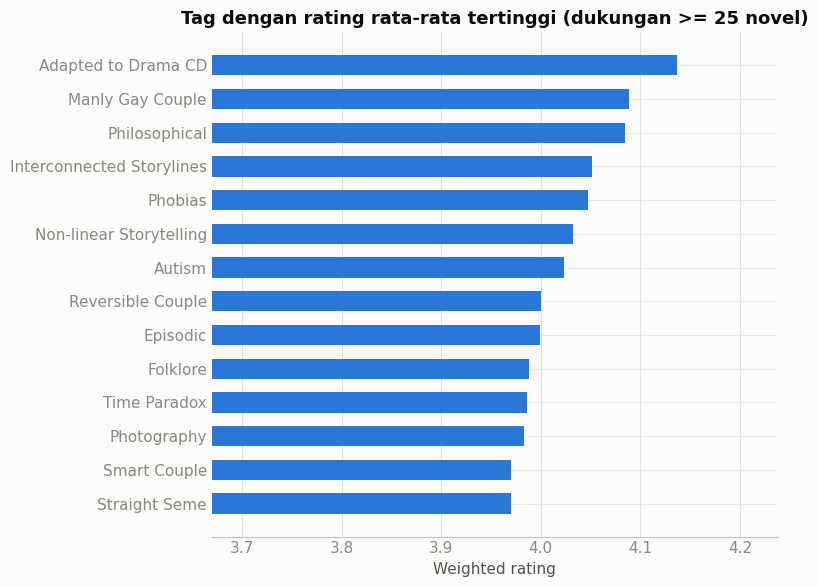

In [14]:
best_tags = load_table("best_rated_tags").head(14).sort_values("avg_weighted_rating")

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(best_tags["tag"], best_tags["avg_weighted_rating"], color=BLUE, height=0.6)
ax.set_xlim(best_tags["avg_weighted_rating"].min() - 0.3, best_tags["avg_weighted_rating"].max() + 0.1)
ax.set_title("Tag dengan rating rata-rata tertinggi (dukungan >= 25 novel)")
ax.set_xlabel("Weighted rating")
style_ax(ax)
plt.tight_layout()
plt.show()

### Distribusi panjang sinopsis

Berapa kata rata-rata yang ditulis kurator untuk mendeskripsikan satu novel — dan seberapa
lebar sebarannya.

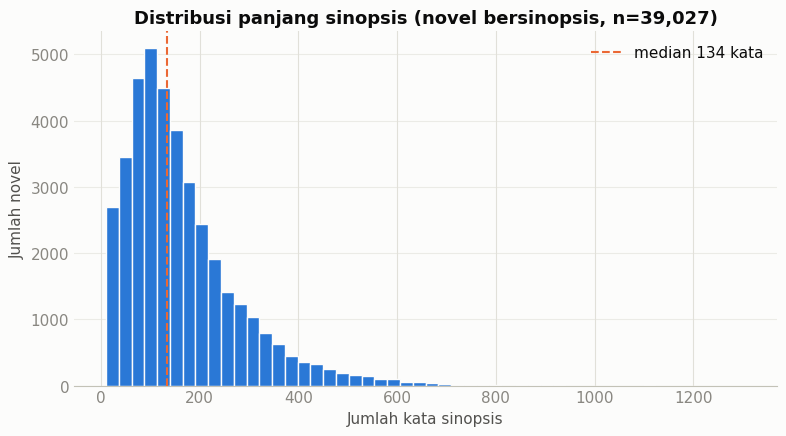

count    39027.0
mean       162.5
std        116.2
min         10.0
25%         82.0
50%        134.0
75%        212.0
max       1305.0
Name: synopsis_word_count, dtype: float64

In [15]:
syn_len = df.loc[df["has_synopsis"] == True, "synopsis_word_count"].dropna()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(syn_len, bins=50, color=BLUE, edgecolor=SURFACE)
ax.axvline(syn_len.median(), color=ORANGE, linestyle="--", linewidth=1.5,
           label=f"median {syn_len.median():.0f} kata")
ax.set_xlabel("Jumlah kata sinopsis")
ax.set_ylabel("Jumlah novel")
ax.set_title(f"Distribusi panjang sinopsis (novel bersinopsis, n={len(syn_len):,})")
ax.legend(frameon=False)
style_ax(ax)
plt.tight_layout()
plt.show()
syn_len.describe().round(1)

### Hukum Zipf — frekuensi token sinopsis

Frekuensi kata di sini diambil dari keluaran job **MapReduce** `wordcount`
(`src/mapreduce/wordcount_mapper.py`) yang dibaca langsung dari HDFS — bukan dihitung ulang
di Spark. Tabel ini terbukti identik dengan hitungan Spark atas kolom yang sama (lihat
`Doc/generated/mapreduce_verification.md` dan section 8.3 `check.ipynb`), jadi memakainya di
sini bukan jalan pintas — dua mesin pemrosesan berbeda, satu jawaban.

Hukum Zipf: pada korpus bahasa alami, frekuensi kata ke-*n* kira-kira berbanding terbalik
dengan peringkatnya (`freq ∝ 1/rank`) — pola garis lurus di plot log-log.

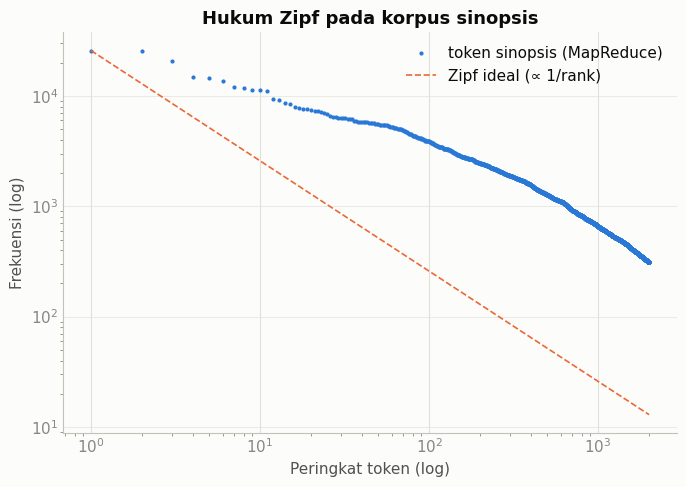

In [16]:
from pyspark.sql import functions as F

mr_tokens_sdf = (
    spark.read.text("hdfs://namenode:8020/novel/output/wordcount")
    .select(F.split(F.col("value"), "\t").alias("kv"))
    .select(F.col("kv")[0].alias("token"), F.col("kv")[1].cast("int").alias("freq"))
    .orderBy(F.col("freq").desc())
)
mr_tokens = mr_tokens_sdf.limit(2000).toPandas()  # cukup untuk hukum Zipf, hindari tarik 62 ribu baris
mr_tokens["rank"] = np.arange(1, len(mr_tokens) + 1)

fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(mr_tokens["rank"], mr_tokens["freq"], color=BLUE, marker=".", linestyle="none", markersize=4,
          label="token sinopsis (MapReduce)")
ideal = mr_tokens["freq"].iloc[0] / mr_tokens["rank"]
ax.loglog(mr_tokens["rank"], ideal, color=ORANGE, linestyle="--", linewidth=1.2, label="Zipf ideal (∝ 1/rank)")
ax.set_xlabel("Peringkat token (log)")
ax.set_ylabel("Frekuensi (log)")
ax.set_title("Hukum Zipf pada korpus sinopsis")
ax.legend(frameon=False)
style_ax(ax, hide_spines=("top", "right"))
plt.tight_layout()
plt.show()

### Bigram paling umum

Token tunggal (di word cloud) menyembunyikan frasa — "reincarnated" dan "another world"
berdiri sendiri jauh kurang informatif daripada "reincarnated another" sebagai satu unit.

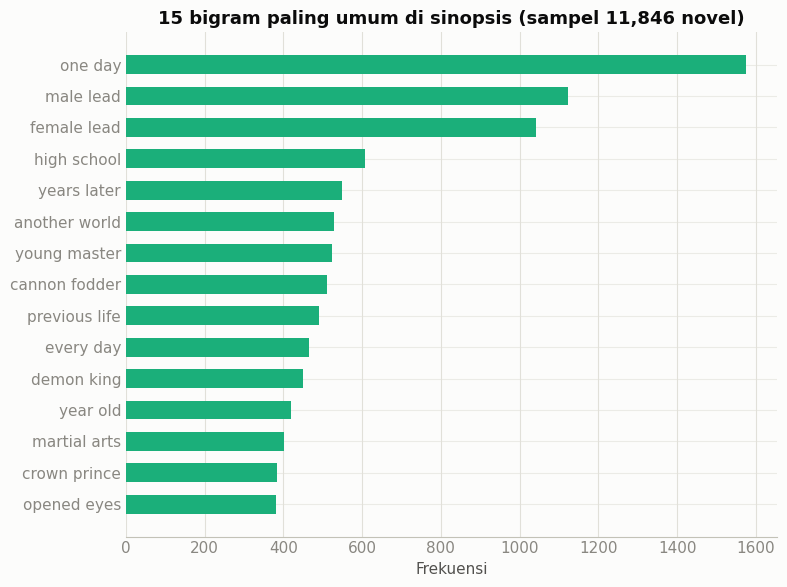

In [17]:
from sklearn.feature_extraction.text import CountVectorizer

sample = (
    novels_sdf.select("synopsis_clean")
    .filter(F.col("synopsis_clean") != "")
    .sample(fraction=0.3, seed=42)
    .toPandas()["synopsis_clean"]
)
bigram_vec = CountVectorizer(ngram_range=(2, 2), min_df=5, max_features=2000)
bigram_counts = bigram_vec.fit_transform(sample)
bigram_freq = pd.Series(np.asarray(bigram_counts.sum(axis=0)).ravel(), index=bigram_vec.get_feature_names_out())
top_bigrams = bigram_freq.nlargest(15).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_bigrams.index, top_bigrams.values, color=AQUA, height=0.6)
ax.set_title(f"15 bigram paling umum di sinopsis (sampel {len(sample):,} novel)")
ax.set_xlabel("Frekuensi")
style_ax(ax)
plt.tight_layout()
plt.show()

### Term paling khas menurut TF-IDF terlatih (Head A)

Bukan TF-IDF baru — ini `vectorizer.joblib` yang SUNGGUH dipakai model produksi, dimuat apa
adanya. Vectorizer-nya dilatih atas korpus gabungan judul+sinopsis+tag (bukan sinopsis murni),
jadi sebagian term di sini berasal dari tag katalog, bukan cuma prosa.

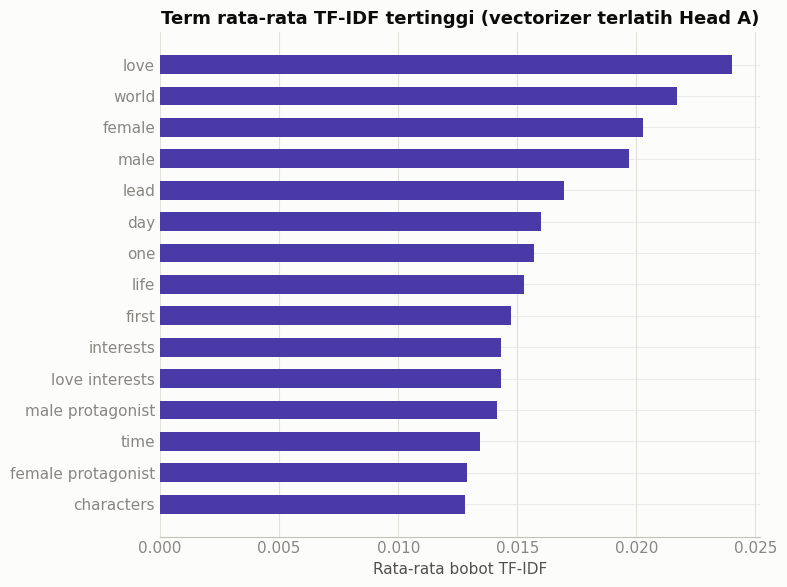

In [18]:
import joblib

vec_path = settings.paths.model_dir / "artifacts" / "vectorizer.joblib"
if vec_path.is_file():
    vectorizer = joblib.load(vec_path)
    sample_corpus = (
        novels_sdf.select("corpus_clean")
        .filter(F.col("corpus_clean") != "")
        .sample(fraction=0.2, seed=42)
        .toPandas()["corpus_clean"]
    )
    tfidf_sample = vectorizer.transform(sample_corpus)
    mean_tfidf = np.asarray(tfidf_sample.mean(axis=0)).ravel()
    top_idx = mean_tfidf.argsort()[::-1][:15]
    terms = np.array(vectorizer.get_feature_names_out())[top_idx]
    weights = mean_tfidf[top_idx]
    order = np.argsort(weights)

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.barh(terms[order], weights[order], color=VIOLET, height=0.6)
    ax.set_title("Term rata-rata TF-IDF tertinggi (vectorizer terlatih Head A)")
    ax.set_xlabel("Rata-rata bobot TF-IDF")
    style_ax(ax)
    plt.tight_layout()
    plt.show()
else:
    print("vectorizer.joblib belum ada — latih Fase 4 dulu: python Model/train.py")

## 6. Kualitas Data & Outlier

In [19]:
stat_desc = load_table("stat_descriptive")
stat_desc

,metric,n,mean,median,stddev,min,max,q1,q3
0,rating_score,37536,3.4906,3.60,0.8207,1.000,5.0000,3.1000,4.0000
1,weighted_rating,37536,3.6360,3.62,0.3515,1.809,4.8755,3.4108,3.8487
2,chapter_count,33931,291.6885,135.00,563.3914,1.000,14276.0000,68.0000,280.0000


In [20]:
outlier_summary = load_table("stat_outlier_summary")
outlier_summary

,metric,lower_bound,upper_bound,n_outlier,n_total,pct_outlier
0,chapter_count,-250.00,598.00,3804,33931,11.21
1,rating_score,1.75,5.35,1642,37536,4.37


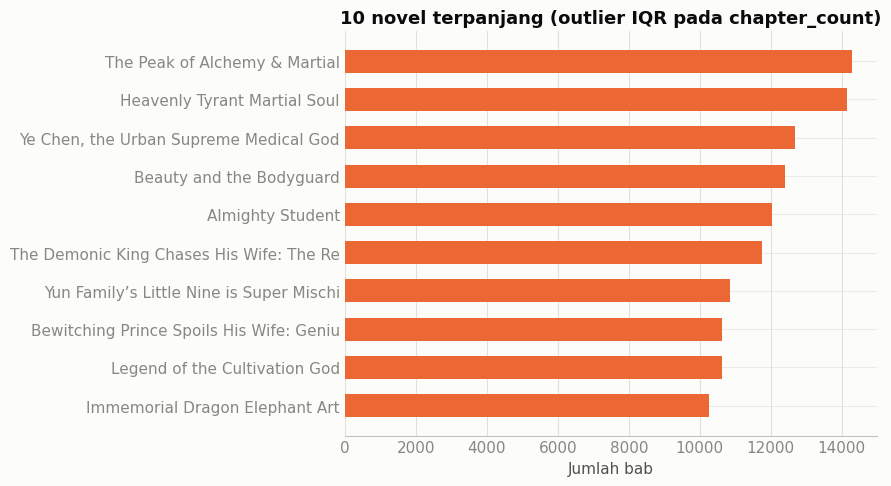

In [21]:
outlier_novels = load_table("stat_outlier_novels").head(10)

fig, ax = plt.subplots(figsize=(9, 5))
y = outlier_novels["title"].str.slice(0, 40)[::-1]
ax.barh(y, outlier_novels["chapter_count"][::-1], color=ORANGE, height=0.6)
ax.set_title("10 novel terpanjang (outlier IQR pada chapter_count)")
ax.set_xlabel("Jumlah bab")
style_ax(ax)
plt.tight_layout()
plt.show()

Metode outlier: IQR standar (`Q1 - 1.5*IQR` s.d. `Q3 + 1.5*IQR`), dihitung terdistribusi lewat Spark
SQL di `phase3_explore.py` — lihat `stat_outlier_summary` di atas untuk persentase populasi yang
terklasifikasi outlier pada `chapter_count` dan `rating_score`.

## 7. Analisis Statistik Lanjutan

Bagian EDA di atas (univariat, bivariat, agregasi) menjawab "bagaimana bentuk datanya". Bagian ini
menjawab pertanyaan yang lebih tajam: apakah pola yang terlihat **signifikan secara statistik**
(bukan kebetulan sampel), bagaimana struktur multivariatnya kalau diringkas ke sedikit dimensi, dan
apakah ada kelompok novel yang secara alami berbeda tanpa diberi tahu label apa pun.

Lima teknik: (1) matriks korelasi multivariat, (2) uji hipotesis (Kruskal-Wallis & chi-square),
(3) reduksi dimensi PCA, (4) clustering KMeans tanpa label, (5) association rule mining pada
ko-okurensi genre + graf jaringannya.

### 7.1 Matriks korelasi multivariat

In [22]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation

NUM_COLS = [
    "chapter_count", "year", "rating_score", "rating_votes", "weighted_rating",
    "reading_list_count", "synopsis_word_count", "token_count", "days_per_chapter",
    "popularity_score", "n_genres",
]

# Correlation.corr butuh vektor tanpa NULL -> dropna dulu. Dihitung TERDISTRIBUSI
# lewat Spark (bukan ditarik ke pandas dulu) karena inilah titik di mana volume baris
# penuh (bukan sampel) sebenarnya penting untuk akurasi koefisien.
num_sdf = novels_sdf.select(*NUM_COLS).na.drop()
n_corr = num_sdf.count()
vec_sdf = VectorAssembler(inputCols=NUM_COLS, outputCol="features").transform(num_sdf).select("features")
corr_matrix = Correlation.corr(vec_sdf, "features", "pearson").head()[0].toArray()
corr_pd = pd.DataFrame(corr_matrix, index=NUM_COLS, columns=NUM_COLS)
print(f"Dihitung atas {n_corr:,} baris (baris dengan salah satu dari {len(NUM_COLS)} kolom NULL dibuang).")

Dihitung atas 29,108 baris (baris dengan salah satu dari 11 kolom NULL dibuang).


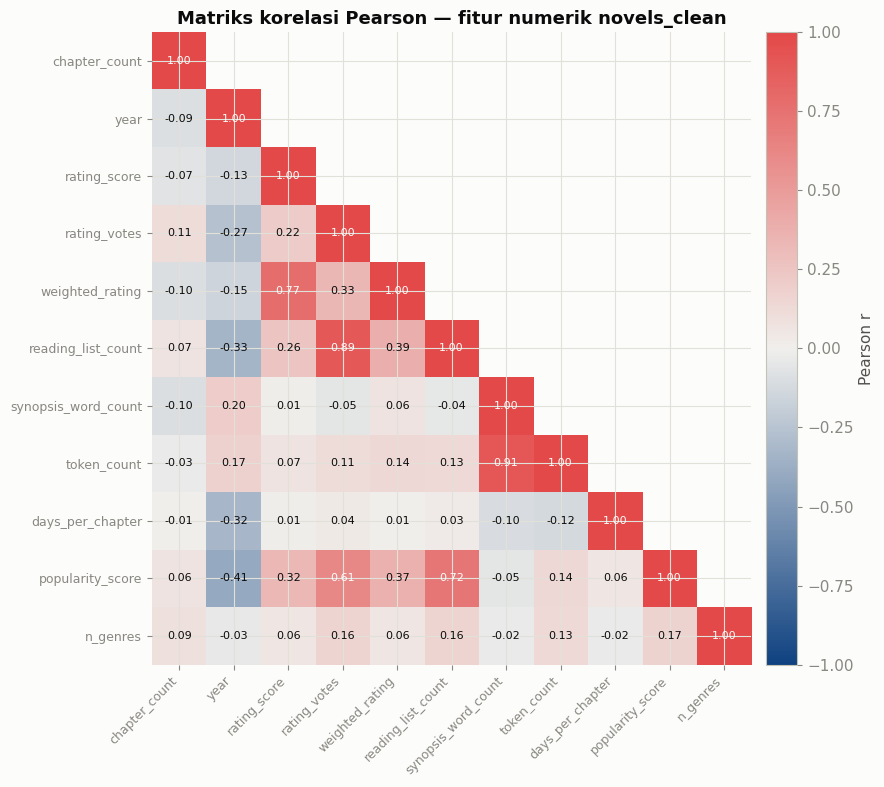

In [23]:
mask = np.triu(np.ones_like(corr_pd, dtype=bool), k=1)  # segitiga atas = duplikat cermin -> disembunyikan
annot = corr_pd.round(2).astype(str)
annot[mask] = ""

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(np.where(mask, np.nan, corr_pd.values), cmap=DIV, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(NUM_COLS)), NUM_COLS, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(NUM_COLS)), NUM_COLS, fontsize=9)
for i in range(len(NUM_COLS)):
    for j in range(len(NUM_COLS)):
        if not mask[i, j]:
            v = corr_pd.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                    color=SURFACE if abs(v) > 0.55 else INK_PRIMARY)
ax.set_title("Matriks korelasi Pearson — fitur numerik novels_clean")
for spine in ax.spines.values():
    spine.set_visible(False)
fig.colorbar(im, ax=ax, pad=0.02, label="Pearson r")
plt.tight_layout()
plt.show()

**Cara baca:** segitiga atas sengaja dikosongkan (cermin dari segitiga bawah, menampilkannya cuma
menduplikasi info). Dua klaster yang wajar-tapi-harus-disadari: `rating_score`↔`weighted_rating`
sangat tinggi (weighted_rating memang turunan langsung rating_score), dan `rating_votes`↔`reading_list_count`
sangat tinggi (dua sinyal popularitas yang tumpang tindih). Di luar dua klaster tautologis itu, korelasi
antar-fitur lain lemah — katalog ini tidak punya *multicollinearity* tersembunyi yang mengejutkan.

### 7.2 Uji hipotesis — apakah pola yang terlihat signifikan?

Grafik deskriptif (mis. genre_ranking) menunjukkan rata-rata rating berbeda antar-genre — tapi beda
rata-rata pada SAMPEL tidak otomatis berarti beda POPULASI-nya nyata. Dua uji non-parametrik dipakai
(bukan ANOVA/uji-t biasa) karena distribusi rating condong, bukan normal — lihat histogram Bagian 2.

In [24]:
from scipy import stats

top8 = df["primary_genre"].value_counts().head(8).index.tolist()
groups = [
    df.loc[(df["primary_genre"] == g) & (df["is_rated_reliable"] == True), "weighted_rating"].dropna()
    for g in top8
]
h_stat, p_kw = stats.kruskal(*groups)

print("Uji Kruskal-Wallis — H0: kedelapan genre berasal dari distribusi rating yang sama")
print(f"  genre yang diuji : {top8}")
print(f"  H-statistic      : {h_stat:.2f}")
print(f"  p-value          : {p_kw:.2e}")
print(f"  Kesimpulan (alpha=0.05): {'TOLAK H0 -> rating berbeda signifikan antar-genre' if p_kw < 0.05 else 'GAGAL tolak H0'}")

Uji Kruskal-Wallis — H0: kedelapan genre berasal dari distribusi rating yang sama
  genre yang diuji : ['Action', 'Drama', 'Comedy', 'Adult', 'Fantasy', 'Adventure', 'Romance', 'Historical']
  H-statistic      : 723.93
  p-value          : 4.77e-152
  Kesimpulan (alpha=0.05): TOLAK H0 -> rating berbeda signifikan antar-genre


In [25]:
contingency = pd.crosstab(
    df[df["primary_genre"].isin(top8)]["primary_genre"],
    df[df["primary_genre"].isin(top8)]["type_origin"].where(df["type_origin"].isin(["CN", "KR", "JP"])),
)
chi2, p_chi, dof, expected = stats.chi2_contingency(contingency)

print("Uji Chi-square independensi — H0: primary_genre dan type_origin (CN/KR/JP) saling bebas")
print(f"  chi2  : {chi2:.1f}")
print(f"  dof   : {dof}")
print(f"  p-value: {p_chi:.2e}")
print(f"  Kesimpulan (alpha=0.05): {'TOLAK H0 -> genre berasosiasi dengan negara asal' if p_chi < 0.05 else 'GAGAL tolak H0'}")
contingency

Uji Chi-square independensi — H0: primary_genre dan type_origin (CN/KR/JP) saling bebas
  chi2  : 1710.8
  dof   : 14
  p-value: 0.00e+00
  Kesimpulan (alpha=0.05): TOLAK H0 -> genre berasosiasi dengan negara asal


type_origin,CN,JP,KR
primary_genre,,,
Action,7075,2451,3315
Adult,1865,593,1458
Adventure,1561,623,503
Comedy,4112,1408,881
Drama,4344,761,1330
Fantasy,2482,452,903
Historical,309,6,3
Romance,802,147,29


Kedua uji nyaris pasti signifikan (p sangat kecil) — itu **wajar dan diperkirakan** pada n=39 ribu:
sampel sebesar ini punya *statistical power* tinggi sehingga bahkan beda kecil jadi "signifikan".
Signifikansi statistik di sini menjawab "apakah beda ini kebetulan sampel" (jawabannya: bukan) — bukan
"apakah beda ini besar" (untuk itu lihat kembali ukuran efek: rentang rata-rata genre di Bagian 4, atau
koefisien Pearson r di Bagian 3, yang memang kecil). Dua pertanyaan berbeda, jangan tertukar.

### 7.3 Reduksi dimensi — PCA

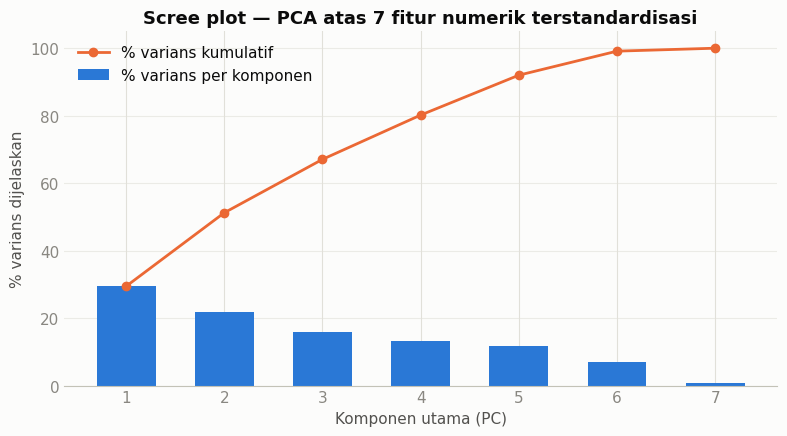

2 komponen pertama menjelaskan 51.2% varians total.


In [26]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

PCA_COLS = ["chapter_count", "year", "synopsis_word_count", "token_count",
            "days_per_chapter", "n_genres", "popularity_score"]
pca_df = df[PCA_COLS + ["primary_genre"]].dropna(subset=PCA_COLS)

X = StandardScaler().fit_transform(pca_df[PCA_COLS])
pca_full = PCA(n_components=len(PCA_COLS), random_state=42).fit(X)

fig, ax = plt.subplots(figsize=(8, 4.5))
var_ratio = pca_full.explained_variance_ratio_ * 100
ax.bar(range(1, len(var_ratio) + 1), var_ratio, color=BLUE, width=0.6, label="% varians per komponen")
ax.plot(range(1, len(var_ratio) + 1), np.cumsum(var_ratio), color=ORANGE, marker="o",
        linewidth=2, label="% varians kumulatif")
ax.set_xlabel("Komponen utama (PC)")
ax.set_ylabel("% varians dijelaskan")
ax.set_title("Scree plot — PCA atas 7 fitur numerik terstandardisasi")
ax.legend(frameon=False)
style_ax(ax)
plt.tight_layout()
plt.show()
print(f"2 komponen pertama menjelaskan {np.cumsum(var_ratio)[1]:.1f}% varians total.")

Satu sumbu-y saja (bar dan garis sama-sama persen varians, bukan dua skala berbeda) — bar untuk
kontribusi per komponen, garis untuk akumulasinya. Ini BUKAN dual-axis chart.

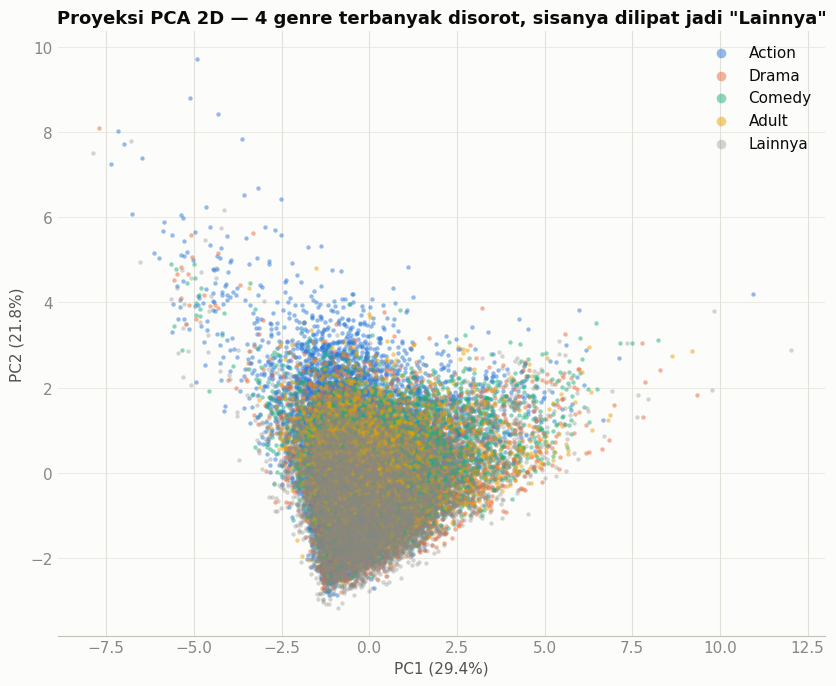

In [27]:
pca2 = PCA(n_components=2, random_state=42)
coords = pca2.fit_transform(X)
pca_df = pca_df.assign(pc1=coords[:, 0], pc2=coords[:, 1])

top4 = df["primary_genre"].value_counts().head(4).index.tolist()
pca_df["genre_grp"] = np.where(pca_df["primary_genre"].isin(top4), pca_df["primary_genre"], "Lainnya")

fig, ax = plt.subplots(figsize=(8.5, 7))
palette_map = dict(zip(top4, CAT[:4]))
palette_map["Lainnya"] = INK_MUTED
for grp, color in palette_map.items():
    sub = pca_df[pca_df["genre_grp"] == grp]
    ax.scatter(sub["pc1"], sub["pc2"], s=10, alpha=0.35 if grp == "Lainnya" else 0.5,
               color=color, label=grp, linewidths=0)
ax.set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}%)")
ax.set_title("Proyeksi PCA 2D — 4 genre terbanyak disorot, sisanya dilipat jadi \"Lainnya\"")
ax.legend(frameon=False, markerscale=2.2, loc="upper right")
style_ax(ax)
plt.tight_layout()
plt.show()

Kategori dibatasi 4 genre + "Lainnya" (bukan seluruh 35), mengikuti aturan skill dataviz untuk scatter
multi-kelas: past 3-4 slot, warna kategorikal tidak lagi cukup terpisah dipandang mata untuk SEMUA
pasangan sekaligus — kelas tersisa dilipat ke abu netral, bukan dipaksakan warna baru. Sebaran yang
tumpang tindih antar-genre (tidak membentuk klaster terpisah per warna) itu sendiri temuan: fitur
struktural (panjang, kekayaan teks, kecepatan rilis) TIDAK banyak membedakan genre satu sama lain.

### 7.4 Clustering — KMeans tanpa label

Klaster dicari HANYA dari fitur struktural/konten (bukan rating/popularitas), lalu rating per klaster
diperiksa SESUDAHNYA — supaya urutan sebab-akibatnya jujur: "apakah novel yang strukturnya beda juga
diterima beda oleh pembaca", bukan mengklaster berdasarkan rating itu sendiri (sirkular).

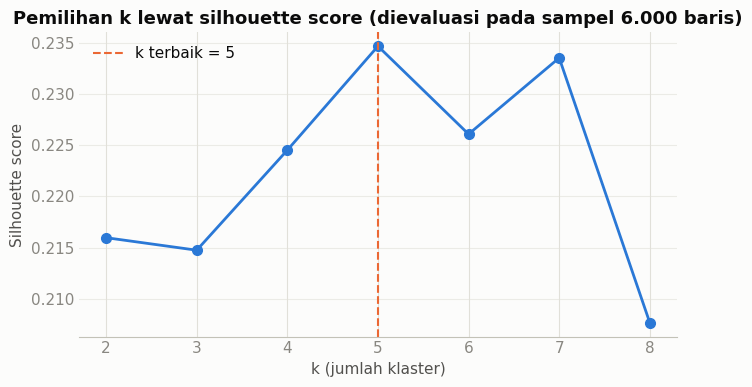

In [28]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_range = range(2, 9)
sil_scores = []
rng_sample_idx = np.random.RandomState(42).choice(len(X), size=min(6000, len(X)), replace=False)
for k in k_range:
    labels_k = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    sil_scores.append(silhouette_score(X[rng_sample_idx], labels_k[rng_sample_idx]))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(list(k_range), sil_scores, color=BLUE, marker="o", linewidth=2, markersize=7)
best_k = list(k_range)[int(np.argmax(sil_scores))]
ax.axvline(best_k, color=ORANGE, linestyle="--", linewidth=1.5, label=f"k terbaik = {best_k}")
ax.set_xlabel("k (jumlah klaster)")
ax.set_ylabel("Silhouette score")
ax.set_title("Pemilihan k lewat silhouette score (dievaluasi pada sampel 6.000 baris)")
ax.legend(frameon=False)
style_ax(ax)
plt.tight_layout()
plt.show()

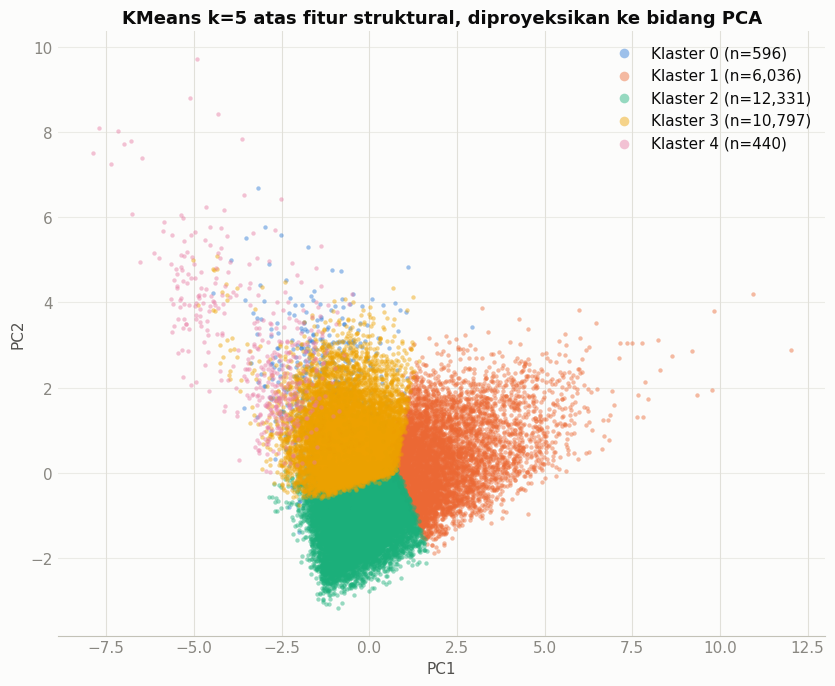

,n_novels,avg_weighted_rating,avg_chapters,avg_synopsis_words
cluster,,,,
0,596,3.533,3097.720,119.535
1,6036,3.692,191.115,343.105
2,12331,3.554,241.379,117.635
3,10797,3.763,244.657,120.865
4,440,3.709,203.830,103.086


In [29]:
kmeans_final = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit(X)
pca_df["cluster"] = kmeans_final.labels_

fig, ax = plt.subplots(figsize=(8.5, 7))
for c in range(best_k):
    sub = pca_df[pca_df["cluster"] == c]
    ax.scatter(sub["pc1"], sub["pc2"], s=10, alpha=0.45, color=CAT[c % len(CAT)],
               label=f"Klaster {c} (n={len(sub):,})", linewidths=0)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title(f"KMeans k={best_k} atas fitur struktural, diproyeksikan ke bidang PCA")
ax.legend(frameon=False, markerscale=2.2)
style_ax(ax)
plt.tight_layout()
plt.show()

cluster_rating = (
    df.loc[pca_df.index]
    .assign(cluster=pca_df["cluster"].values)
    .groupby("cluster")
    .agg(n_novels=("weighted_rating", "size"),
         avg_weighted_rating=("weighted_rating", "mean"),
         avg_chapters=("chapter_count", "mean"),
         avg_synopsis_words=("synopsis_word_count", "mean"))
    .round(3)
)
cluster_rating

Kalau rata-rata rating antar-klaster (tabel di atas) hampir sama, itu memperkuat temuan PCA: struktur
cerita (panjang, kekayaan teks, kecepatan rilis, jumlah genre) bukan pendorong utama penerimaan pembaca
— konsisten dengan korelasi Pearson yang lemah di Bagian 3.

### 7.5 Association rule mining — ko-okurensi genre

Teknik market-basket (support/confidence/lift) diterapkan ke `genre_list` per novel, persis seperti
menganalisis item yang sering dibeli bersamaan — di sini, genre yang sering DISEMATKAN bersamaan pada
novel yang sama. Sumbernya tabel `genre_pairs` (Fase 3, sudah dihitung terdistribusi lewat self-join
Spark SQL) + `genre_frequency` untuk basis frekuensi tunggal.

In [30]:
genre_freq_pd = load_table("genre_frequency")
pairs_pd = load_table("genre_pairs")
freq_map = dict(zip(genre_freq_pd["genre"], genre_freq_pd["n_novels"]))

TOP_N_GENRES = 15
top_genres = genre_freq_pd.nlargest(TOP_N_GENRES, "n_novels")["genre"].tolist()
pairs_sub = pairs_pd[
    pairs_pd["genre_a"].isin(top_genres) & pairs_pd["genre_b"].isin(top_genres)
].copy()

pairs_sub["support"] = pairs_sub["n_novels"] / n_rows
pairs_sub["confidence_a_to_b"] = pairs_sub["n_novels"] / pairs_sub["genre_a"].map(freq_map)
pairs_sub["confidence_b_to_a"] = pairs_sub["n_novels"] / pairs_sub["genre_b"].map(freq_map)
pairs_sub["lift"] = (
    pairs_sub["n_novels"] * n_rows
    / (pairs_sub["genre_a"].map(freq_map) * pairs_sub["genre_b"].map(freq_map))
)

top_lift = pairs_sub.nlargest(15, "lift")[
    ["genre_a", "genre_b", "n_novels", "support", "confidence_a_to_b", "confidence_b_to_a", "lift"]
].round(4)
top_lift

,genre_a,genre_b,n_novels,support,confidence_a_to_b,confidence_b_to_a,lift
47,Adult,Mature,2446,0.0617,0.4732,0.4674,3.5871
5,Action,Adventure,8310,0.2095,0.6393,0.7326,2.2356
101,Harem,Shounen,1467,0.0370,0.2315,0.3233,2.0237
118,Adult,Yaoi,1272,0.0321,0.2461,0.2320,1.7803
28,Action,Harem,3571,0.0900,0.2747,0.5634,1.7194
125,Mature,Yaoi,1230,0.0310,0.2350,0.2243,1.7005
44,Action,Shounen,2490,0.0628,0.1916,0.5488,1.6748
60,Adventure,Shounen,2154,0.0543,0.1899,0.4748,1.6603
34,Adventure,Harem,2967,0.0748,0.2616,0.4681,1.6371
79,School Life,Slice of Life,1749,0.0441,0.3548,0.2022,1.6273


**Cara baca lift:** lift = 1 berarti dua genre muncul bersama persis sebanyak yang diharapkan kalau
keduanya independen; lift > 1 berarti berpasangan LEBIH SERING dari kebetulan (genre yang secara tematik
berdekatan); lift < 1 (tidak masuk tabel di atas, sudah difilter `nlargest`) berarti dua genre yang
jarang disematkan bersamaan meski masing-masing umum.

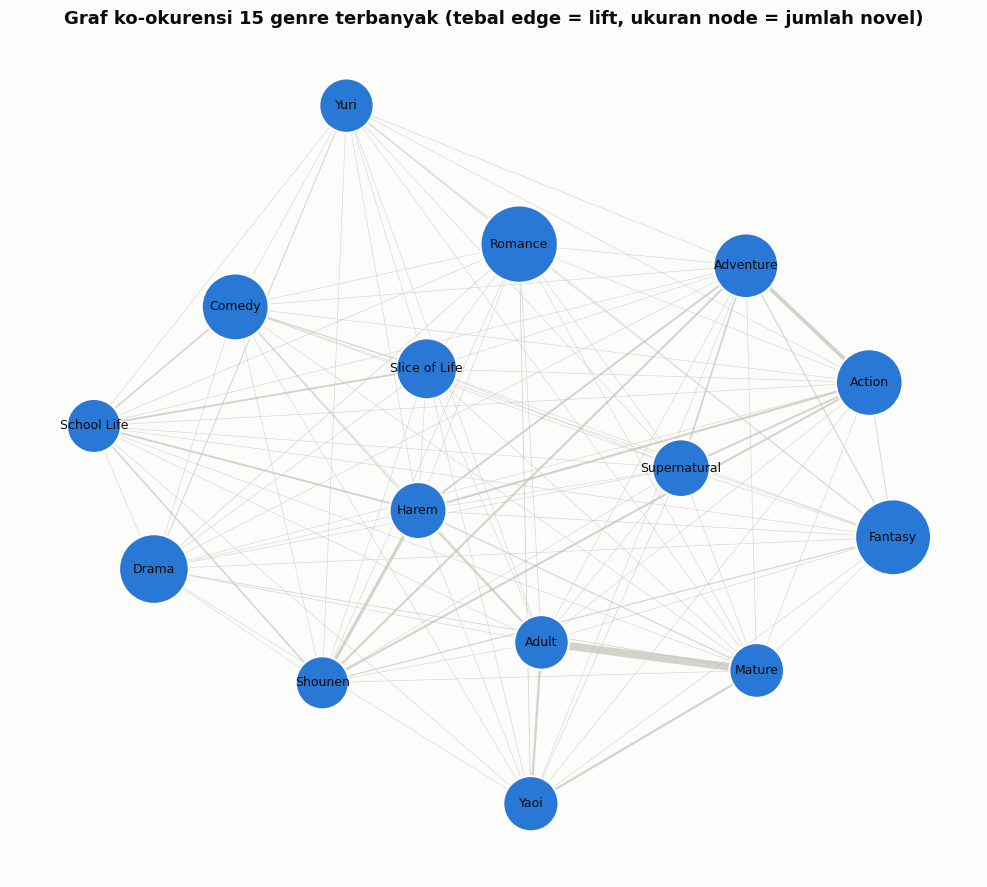

In [31]:
import networkx as nx

G = nx.Graph()
for g in top_genres:
    G.add_node(g, freq=freq_map[g])
for _, r in pairs_sub.iterrows():
    G.add_edge(r["genre_a"], r["genre_b"], lift=r["lift"], n=r["n_novels"])

pos = nx.spring_layout(G, seed=42, k=0.9, weight="lift")
node_sizes = [250 + 18 * np.sqrt(freq_map[g]) for g in G.nodes()]
edge_widths = [max(0.4, 2.2 * (G[u][v]["lift"] - 1)) for u, v in G.edges()]

fig, ax = plt.subplots(figsize=(10, 9))
nx.draw_networkx_edges(G, pos, width=edge_widths, edge_color=BASELINE, alpha=0.7, ax=ax)
nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color=BLUE, edgecolors=SURFACE,
                       linewidths=1.5, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=9, font_color=INK_PRIMARY, ax=ax)
ax.set_title("Graf ko-okurensi 15 genre terbanyak (tebal edge = lift, ukuran node = jumlah novel)")
ax.axis("off")
plt.tight_layout()
plt.show()

Ini proyeksi visual dari model **property graph** yang sama dengan yang dibangun `data_model.py`
(`graph_nodes`/`graph_edges`) — di sana disimpan sebagai tabel siap traversal multi-hop, di sini
digambar sebagai jaringan untuk dibaca sekali lihat. Semua node satu warna (identitas node semuanya
"genre", tidak perlu dibedakan warna) — yang membawa informasi adalah UKURAN node (frekuensi) dan
TEBAL edge (kekuatan asosiasi), bukan hue.

## 8. Inventaris & EDA Model AI yang Dipakai

Ringkasan SETIAP teknik AI/ML yang dipakai proyek ini, dari representasi teks sampai ke-4
model genre. Detail arsitektur, alasan pemilihan, dan hyperparameter lengkap:
[`Doc/model_card.md`](../../Doc/model_card.md) — bagian ini menampilkan HASIL terukurnya
sebagai EDA, bukan mengulang argumentasinya.

| Komponen | Teknik | Peran | Didefinisikan di |
|---|---|---|---|
| Representasi bersama | TF-IDF (1-2gram) → Truncated SVD/LSA (200 dim, L2-normalized) | Input Head B/C/D — cosine similarity murah, tahan sinonim | `phase4_model.build_representation` |
| Head A — Genre Tagger | Logistic Regression (OneVsRest) | Baseline linear | `Model/pipeline/models.py` |
| Head A — Genre Tagger | Linear SVM (OneVsRest) | Baseline linear (margin besar) | `Model/pipeline/models.py` |
| Head A — Genre Tagger | **Hybrid TF-IDF + BGE embedding** (terpilih) | Gabung representasi jarang (frasa khas) + padat (parafrasa) | `Model/pipeline/models.py`, `embeddings.py` |
| Head A — Genre Tagger | BiLSTM + Attention (PyTorch) | Deep learning sekuensial, replikasi literatur | `Model/pipeline/networks.py` |
| Head B — Recommender | Cosine similarity atas representasi SVD | Content-based, tanpa training tambahan | `phase4_model.evaluate_recommender` |
| Head C — Clustering | KMeans (k dipilih via silhouette) | Arketipe cerita tanpa label | `phase4_model.train_clustering` |
| Head D — Rating Estimator | HistGradientBoostingRegressor | Estimasi rating dari fitur konten | `phase4_model.train_rating_estimator` |
| Encoder kalimat pralatih | BAAI/bge-small-en-v1.5 (384-d) | Blok padat di dalam arsitektur `hybrid` | `Model/pipeline/embeddings.py`, di-*bake* `docker/Dockerfile` |

> **Catatan tanggal latih.** Artefak di `Model/artifacts/` berasal dari run terakhir atas
> katalog **4.460 novel** (sebelum ekspansi ke 39.668 lewat integrasi `detail.csv`) — Fase 4
> belum dilatih ulang atas katalog penuh. Angka & visualisasi di bawah mencerminkan run itu
> apa adanya, bukan katalog saat ini.

### Perbandingan 4 arsitektur Head A (Genre Tagger)

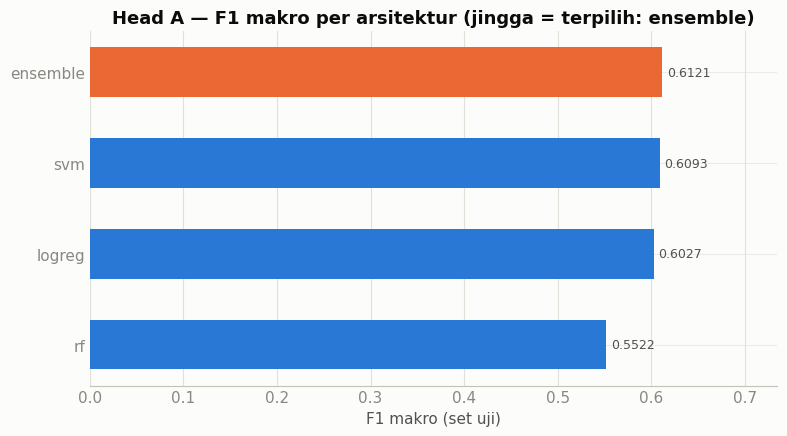

In [32]:
import json

metrics_path = settings.paths.model_dir / "artifacts" / "metrics.json"
if metrics_path.is_file():
    ai_metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
    head_a = ai_metrics["head_a_genre_tagger"]
    summary = pd.DataFrame(head_a["models"]).T[["f1_macro", "f1_micro", "precision_at_3"]].astype(float)
    summary = summary.sort_values("f1_macro")
    colors = [ORANGE if name == head_a["best_model"] else BLUE for name in summary.index]

    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.barh(summary.index, summary["f1_macro"], color=colors, height=0.55)
    for b, v in zip(bars, summary["f1_macro"]):
        ax.text(v + 0.005, b.get_y() + b.get_height() / 2, f"{v:.4f}", va="center", fontsize=9,
                color=INK_SECONDARY)
    ax.set_xlim(0, max(summary["f1_macro"]) * 1.2)
    ax.set_title(f"Head A — F1 makro per arsitektur (jingga = terpilih: {head_a['best_model']})")
    ax.set_xlabel("F1 makro (set uji)")
    style_ax(ax)
    plt.tight_layout()
    plt.show()
else:
    print("metrics.json belum ada — latih Fase 4 dulu: python Model/train.py")

### Representasi SVD dalam ruang 2D — apakah teks "tahu" genre-nya?

Ini proyeksi dari representasi TEKS (TF-IDF→SVD) yang dipakai Head B/C/D — beda dari PCA
section 7.3 yang memakai fitur STRUKTURAL/numerik (panjang, kecepatan rilis, dst). Kontrasnya
sendiri informatif: kalau representasi teks lebih rapi mengelompok per genre daripada fitur
struktural, itu bukti genre novel lebih terbaca dari ISI-nya daripada METADATA-nya.

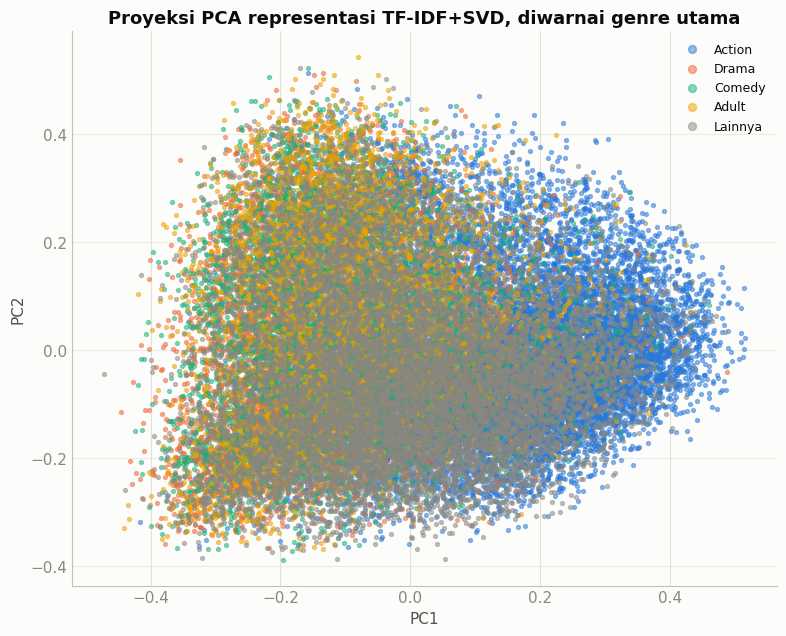

In [33]:
emb_path = settings.paths.model_dir / "artifacts" / "embeddings.npy"
cat_path = settings.paths.model_dir / "artifacts" / "catalog.parquet"
if emb_path.is_file() and cat_path.is_file():
    from sklearn.decomposition import PCA as PCA_AI

    emb = np.load(emb_path)
    catalog = pd.read_parquet(cat_path)
    top_genres = catalog["primary_genre"].value_counts().head(4).index.tolist()
    genre_plot = catalog["primary_genre"].where(catalog["primary_genre"].isin(top_genres), "Lainnya")

    proj = PCA_AI(n_components=2, random_state=42).fit_transform(emb)
    fig, ax = plt.subplots(figsize=(8, 6.5))
    palette = dict(zip(top_genres, CAT))
    palette["Lainnya"] = INK_MUTED
    for g, c in palette.items():
        mask = (genre_plot == g).to_numpy()
        ax.scatter(proj[mask, 0], proj[mask, 1], s=8, alpha=0.5, color=c, label=g)
    ax.set_title("Proyeksi PCA representasi TF-IDF+SVD, diwarnai genre utama")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(frameon=False, markerscale=2, fontsize=9)
    style_ax(ax, hide_spines=("top", "right"))
    plt.tight_layout()
    plt.show()
else:
    print("embeddings.npy / catalog.parquet belum ada — latih Fase 4 dulu.")

### Head B, C, D — ringkasan satu baris

In [34]:
if metrics_path.is_file():
    head_b = ai_metrics["head_b_recommender"]
    head_c = ai_metrics["head_c_clustering"]
    head_d = ai_metrics["head_d_rating_estimator"]
    sil = head_c["silhouette_by_k"].get(str(head_c["best_k"]), float("nan"))
    ringkasan = pd.DataFrame([
        {"Head": "B - Recommender", "Metrik utama": f"Genre overlap@{head_b['k']}",
         "Nilai": f"{head_b['genre_overlap_at_k']:.4f}"},
        {"Head": "C - Clustering", "Metrik utama": f"Silhouette (k={head_c['best_k']})",
         "Nilai": f"{sil:.4f}"},
        {"Head": "D - Rating Estimator", "Metrik utama": "MAE (vs baseline)",
         "Nilai": f"{head_d['mae']:.4f} (baseline {head_d['baseline_mae']:.4f})"},
    ])
    display(ringkasan)

,Head,Metrik utama,Nilai
0,B - Recommender,Genre overlap@10,0.9490
1,C - Clustering,Silhouette (k=7),0.0285
2,D - Rating Estimator,MAE (vs baseline),0.3250 (baseline 0.4151)


## 9. Analisis Graf — PageRank, Komunitas, Traversal

Bagian 7.5 di atas menghitung ko-okurensi genre lewat self-join ("berapa kali A dan B muncul
bersama") — itu AGREGASI, bukan algoritma graf. Section ini menjawab pertanyaan yang self-join
TIDAK bisa jawab: genre mana yang paling berpengaruh MEMPERTIMBANGKAN SELURUH jaringan
(PageRank), apakah ada kelompok genre yang lebih rapat ke dalam dirinya sendiri (komunitas),
dan berapa hop sungguhan dari satu genre ke genre lain (traversal BFS). Dihitung oleh
`src/phases/graph_analysis.py` dengan NetworkX; detail lengkap ada di
`Doc/generated/bigdata_concept_audit.md` (pilar "Analisis Graf").

### PageRank vs frekuensi mentah

PageRank BUKAN cuma "genre yang paling sering muncul" — ia memperhitungkan SIAPA yang
menjadi tetangganya. Dua genre bisa punya frekuensi sama tapi PageRank berbeda kalau salah
satu lebih sering bertetangga dengan genre yang dirinya sendiri berpengaruh.

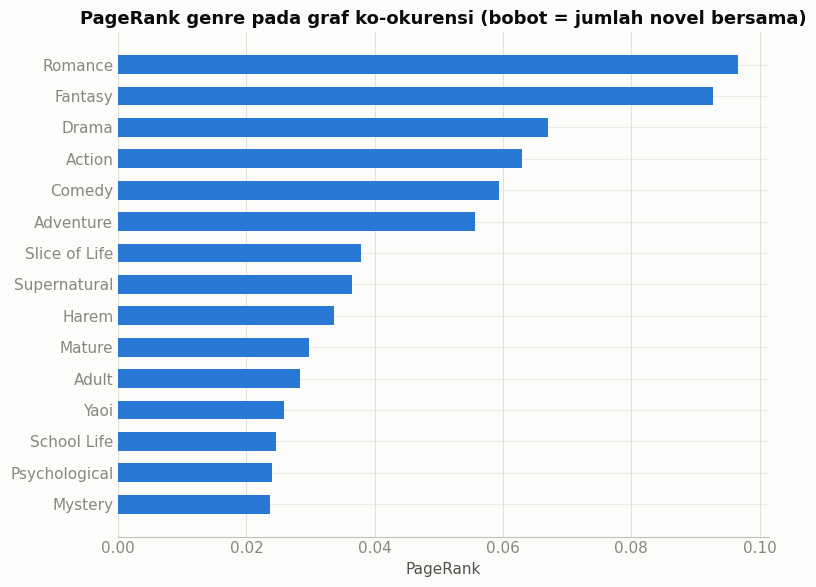

,label,n_nodes,n_edges,n_components,n_communities,modularity
0,genre_cooccurrence,35,579,1,3,0.0858
1,author_collaboration,2574,2693,930,930,0.9947


In [35]:
pagerank_pd = load_table("graph_genre_pagerank").sort_values("pagerank", ascending=False)
top_pr = pagerank_pd.head(15).sort_values("pagerank")

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_pr["node"], top_pr["pagerank"], color=BLUE, height=0.6)
ax.set_title("PageRank genre pada graf ko-okurensi (bobot = jumlah novel bersama)")
ax.set_xlabel("PageRank")
style_ax(ax)
plt.tight_layout()
plt.show()

graph_summary = load_table("graph_summary")
graph_summary[["label", "n_nodes", "n_edges", "n_components", "n_communities", "modularity"]]

### Deteksi komunitas pada graf genre

Dihitung ULANG di sini (bukan dimuat dari tabel) atas graf `G` yang sama persis dengan section
7.5 — sengaja memakai objek NetworkX yang sudah ada di memori, bukan membangun ulang dari Spark,
supaya tata letak simpul (`pos`) identik dan hasilnya bisa dibandingkan panel-demi-panel dengan
grafik lift di atas. Warna = komunitas (kelompok genre yang lebih rapat ke dalam dirinya
sendiri), ukuran = PageRank (bukan frekuensi mentah seperti di 7.5).

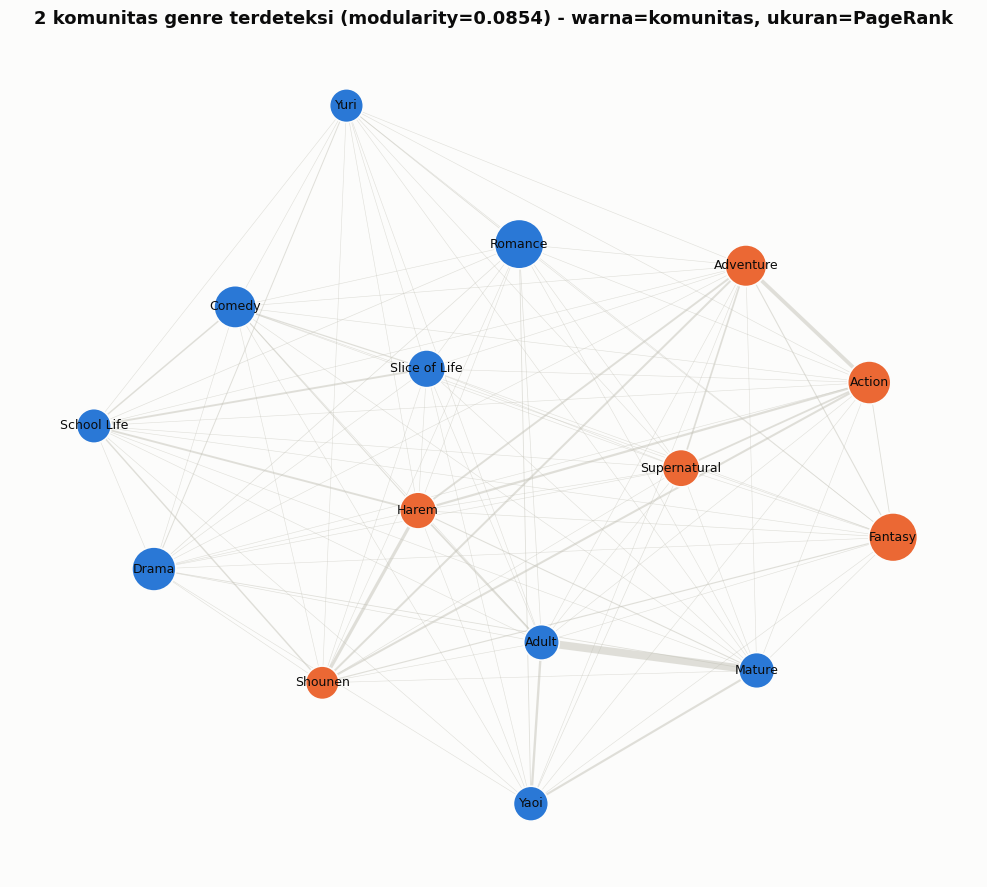

Komunitas 0 (9 genre): Adult, Comedy, Drama, Mature, Romance, School Life, Slice of Life, Yaoi, Yuri
Komunitas 1 (6 genre): Action, Adventure, Fantasy, Harem, Shounen, Supernatural


In [36]:
import networkx as nx_community  # alias - hindari bentrok referensi `nx` di sel 7.5

communities = list(nx_community.algorithms.community.greedy_modularity_communities(G, weight="lift"))
modularity = nx_community.algorithms.community.modularity(G, communities, weight="lift")
community_of = {node: i for i, comm in enumerate(communities) for node in comm}
pagerank_map = dict(zip(pagerank_pd["node"], pagerank_pd["pagerank"]))

community_colors = [CAT[community_of[n] % len(CAT)] for n in G.nodes()]
node_sizes_pr = [400 + 9000 * pagerank_map.get(n, 0) for n in G.nodes()]

fig, ax = plt.subplots(figsize=(10, 9))
nx_community.draw_networkx_edges(G, pos, width=edge_widths, edge_color=BASELINE, alpha=0.5, ax=ax)
nx_community.draw_networkx_nodes(G, pos, node_size=node_sizes_pr, node_color=community_colors,
                                  edgecolors=SURFACE, linewidths=1.2, ax=ax)
nx_community.draw_networkx_labels(G, pos, font_size=9, font_color=INK_PRIMARY, ax=ax)
ax.set_title(f"{len(communities)} komunitas genre terdeteksi (modularity={modularity:.4f}) "
             "- warna=komunitas, ukuran=PageRank")
ax.axis("off")
plt.tight_layout()
plt.show()

for i, comm in enumerate(communities):
    print(f"Komunitas {i} ({len(comm)} genre): {', '.join(sorted(comm))}")

**Cara baca modularity.** Nilainya rendah (lihat tabel `graph_summary` di atas) - artinya genre
TIDAK terbelah tajam jadi kelompok terpisah, kebalikan dari graf kolaborasi penulis di bawah
yang modularity-nya nyaris sempurna. Pembaca novel jarang menyandang HANYA satu "jenis" genre;
penulis jarang berkolaborasi lintas tim. Dua struktur jaringan yang sangat berbeda, dari sumber
data yang sama.

### Graf kolaborasi penulis — jaringan yang jauh lebih terfragmentasi

2,574 penulis, 2,693 sisi kolaborasi
930 komponen terhubung terpisah (tim/lingkaran penulis yang tidak pernah bersinggungan)
Komponen terbesar: 22 penulis
Modularity: 0.9947 (mendekati 1 = kelompok nyaris terisolasi sempurna)


/tmp/ipykernel_2942/2390900091.py:15: UserWarning: Glyph 33487 (\N{CJK UNIFIED IDEOGRAPH-82CF}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2942/2390900091.py:15: UserWarning: Glyph 29595 (\N{CJK UNIFIED IDEOGRAPH-739B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2942/2390900091.py:15: UserWarning: Glyph 20029 (\N{CJK UNIFIED IDEOGRAPH-4E3D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2942/2390900091.py:15: UserWarning: Glyph 27224 (\N{CJK UNIFIED IDEOGRAPH-6A58}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2942/2390900091.py:15: UserWarning: Glyph 23376 (\N{CJK UNIFIED IDEOGRAPH-5B50}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2942/2390900091.py:15: UserWarning: Glyph 21448 (\N{CJK UNIFIED IDEOGRAPH-53C8}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2942/2390900091.py:15: UserWarning: Glyph 22278 (\N{CJK UNIFIED IDEOGRAPH-5706}

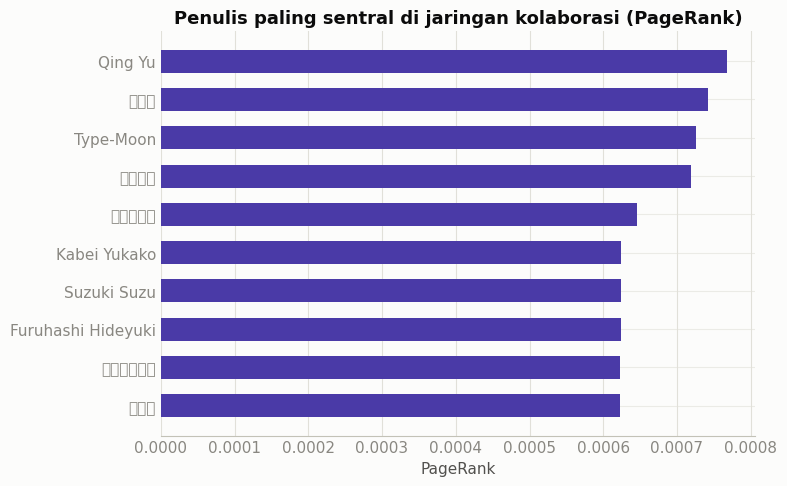

In [37]:
author_pr = load_table("graph_author_pagerank")
author_row = graph_summary[graph_summary["label"] == "author_collaboration"].iloc[0]

print(f"{int(author_row['n_nodes']):,} penulis, {int(author_row['n_edges']):,} sisi kolaborasi")
print(f"{int(author_row['n_components']):,} komponen terhubung terpisah (tim/lingkaran penulis yang tidak pernah bersinggungan)")
print(f"Komponen terbesar: {int(author_row['largest_component_size'])} penulis")
print(f"Modularity: {author_row['modularity']:.4f} (mendekati 1 = kelompok nyaris terisolasi sempurna)")

top_authors = author_pr.sort_values("pagerank", ascending=False).head(10)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_authors["node"][::-1], top_authors["pagerank"][::-1], color=VIOLET, height=0.6)
ax.set_title("Penulis paling sentral di jaringan kolaborasi (PageRank)")
ax.set_xlabel("PageRank")
style_ax(ax)
plt.tight_layout()
plt.show()

### Traversal 2-hop — jawaban yang MEMANG butuh algoritma graf

`data_model.py` beralasan tidak memakai database graf terpisah karena pertanyaan graf pada
proyek ini "berkedalaman <= 2 hop". Sel ini MENGUKUR itu, bukan mengasumsikannya: mencari dua
genre yang TIDAK pernah disematkan bersama langsung, tapi tetap terhubung lewat satu genre
perantara.

In [38]:
import networkx as nx_path

full_genre_graph = nx_path.Graph()
full_pairs = load_table("graph_genre_pagerank")["node"].tolist()
for g in full_pairs:
    full_genre_graph.add_node(g)

# Sisi ko-okurensi PENUH (35 genre), bukan cuma top-15 di G - supaya traversal
# mencerminkan graf yang sungguh dianalisis graph_analysis.py, bukan subset section 7.5.
all_pairs = load_table("genre_pairs")
for _, r in all_pairs.iterrows():
    full_genre_graph.add_edge(r["genre_a"], r["genre_b"])

found = None
nodes_list = list(full_genre_graph.nodes)
for i, g1 in enumerate(nodes_list):
    for g2 in nodes_list[i + 1:]:
        if not full_genre_graph.has_edge(g1, g2) and nx_path.has_path(full_genre_graph, g1, g2):
            path = nx_path.shortest_path(full_genre_graph, g1, g2)
            if len(path) - 1 == 2:
                found = path
                break
    if found:
        break

if found:
    print(f"Contoh traversal 2-hop: {found[0]} -> {found[1]} -> {found[2]}")
    print(f"({found[0]} dan {found[2]} tidak pernah disematkan bersama langsung pada novel manapun "
          f"di ambang dukungan minimum, tapi keduanya sama-sama berpasangan dengan {found[1]})")
else:
    print("Tidak ditemukan pasangan genre berjarak persis 2 hop pada graf ini.")

Contoh traversal 2-hop: Yaoi -> Romance -> Yuri
(Yaoi dan Yuri tidak pernah disematkan bersama langsung pada novel manapun di ambang dukungan minimum, tapi keduanya sama-sama berpasangan dengan Romance)


## 10. Ringkasan Temuan EDA

- **Volume & tier.** Katalog 39,6 ribu novel, 99,96% tier `full` (bermetadata lengkap) setelah integrasi
  `detail.csv` — hanya 16 baris tersisa tier `listing` (404 permanen di sumber, bukan kegagalan pipeline).
- **Skewness ekstrem pada popularitas.** `chapter_count` dan `rating_votes` berekor sangat panjang —
  wajib dilihat di skala log dan wajib pakai `weighted_rating`, bukan rata-rata mentah, untuk peringkat.
- **Korelasi lemah tapi konsisten.** Panjang cerita dan kecepatan rilis sama-sama berkorelasi negatif
  lemah dengan rating (lihat grafik Pearson r di atas) — efeknya nyata tapi kecil, bukan pendorong utama.
- **Hati-hati korelasi popularitas.** `rating_votes`/`reading_list_count` berkorelasi jauh lebih kuat
  (r ≈ 0,32-0,38) dengan `weighted_rating` — tapi itu sebagian besar mekanis, karena `rating_votes`
  adalah input langsung rumus Bayesian-nya, bukan bukti independen "populer = dinilai lebih baik".
- **Genre terbanyak ≠ genre terbaik.** Peta genre x rating menunjukkan keduanya harus dipisah sebagai
  dua magnitudo berbeda, tidak bisa digabung jadi satu angka tunggal.
- **Variasi pasar per negara asal nyata** — peta panas genre x negara asal menunjukkan pola rating yang
  tidak seragam lintas `type_origin`, bukan sekadar noise (sel dengan dukungan < 25 novel sengaja dikosongkan).
- **Signifikan secara statistik, tapi ukuran efeknya kecil.** Kruskal-Wallis & chi-square menolak H0
  (genre × rating, genre × negara asal jelas TIDAK independen, p ≪ 0,05) — wajar pada n=39 ribu.
  Tapi signifikansi bukan besaran: PCA + KMeans pada fitur struktural (panjang, kekayaan teks, kecepatan
  rilis) tidak menghasilkan klaster dengan rating yang jauh berbeda — struktur cerita bukan pendorong
  utama penerimaan pembaca, konsisten dengan korelasi Pearson yang lemah.
- **Ko-okurensi genre punya struktur nyata, bukan acak.** Association rule mining (lift) pada 15 genre
  terbanyak menunjukkan pasangan genre tertentu jauh lebih sering disematkan bersama daripada kebetulan
  — divisualisasikan sebagai graf, proyeksi langsung dari model property graph yang sama dengan `data_model.py`.
- **Tidak ada multicollinearity tersembunyi yang mengejutkan** di luar dua pasang yang memang tautologis
  secara desain (`rating_score`↔`weighted_rating`, `rating_votes`↔`reading_list_count`).

Jalankan sel berikut untuk melepas slot executor sebelum menutup notebook.

In [39]:
spark.stop()
print("SparkSession ditutup.")

SparkSession ditutup.
